# Is Higher College Tuition Associated with Higher Graduate Earnings?

**CISC7204 Data Science and Data Visualization · Class F Team 05**

This notebook implements the analysis plan in the team proposal. It runs from top to bottom in a clean session and recreates every cleaned dataset, result table and static figure.

| Section | Content |
|---|---|
| 0 | Setup and source log |
| 1 | Data preparation: CPI, RPP, institution data, sample flow, field-of-study data |
| 2 | Q1 Main relationship and all sensitivity checks |
| 3 | Q2 Student background (SAT and family income) |
| 4 | Q3 Regional prices (state RPP) |
| 5 | Q4 Field of study (8 common fields; 8 interaction models, 16 sector slopes) |
| 6 | Summary of findings |

**Inputs** (raw files are never modified): `../dataset/` (College Scorecard, BEA RPP, BLS CPI-U and state boundaries).
**Outputs**: `../data_clean/` (cleaned and merged data), `../results/` (tables) and `../figures/` (static figures). The Plotly Dash dashboard in `../dashboard/` reads these outputs.

The study is observational: every estimate below describes an association across institutions, not the effect of paying more tuition.

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import norm
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, Polygon
from matplotlib.ticker import FuncFormatter
import json

warnings.filterwarnings("ignore", message="Workbook contains no default style")

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "dataset").is_dir() and (p / "notebook").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the extracted Team05 project folder.")
RAW = ROOT / "dataset"
CPI_FILE = RAW / "CPI_2011-2024(1).xlsx"
CLEAN, RES, FIG = ROOT / "data_clean", ROOT / "results", ROOT / "figures"
for folder in (CLEAN, RES, FIG):
    folder.mkdir(exist_ok=True)

NA_CODES = ["PrivacySuppressed", "PS", "NULL", "NA", ""]
TUITION_YEARS = ["2011_12", "2012_13", "2013_14", "2014_15", "2015_16"]
TUITION_WEIGHTS = dict(zip(TUITION_YEARS, [1, 2, 2, 2, 1]))   # two overlapping four-year windows
TYPE_LABELS = {1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}
MAIN_TYPES = ["Public", "Private nonprofit"]
STATE_NAMES = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA",
    "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE", "District of Columbia": "DC",
    "Florida": "FL", "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL",
    "Indiana": "IN", "Iowa": "IA", "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN",
    "Mississippi": "MS", "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR",
    "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA",
    "Washington": "WA", "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
}
STATE_CODES = set(STATE_NAMES.values())

# Colour-blind-safe categorical slots (validated all-pairs for three series) and neutral ink.
COLORS = {"Public": "#2a78d6", "Private nonprofit": "#eb6834", "Private for-profit": "#1baf7a"}
INK, INK2, GRID, NODATA = "#0b0b0b", "#52514e", "#e4e3df", "#c9c8c2"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
SOURCE = "Source: U.S. Department of Education, College Scorecard; BEA Regional Price Parities; BLS CPI-U."
Z = norm.ppf(0.975)

plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 11, "axes.labelsize": 11, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5, "legend.fontsize": 11, "axes.edgecolor": INK2,
    "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.dpi": 200, "savefig.bbox": "tight", "legend.frameon": False,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
dollars = FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")
no_label = FuncFormatter(lambda v, _: "")


def log_axes(ax, xticks, yticks):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(dollars)
        axis.set_minor_formatter(no_label)


def footer(fig, text, y=-0.02):
    fig.text(0.01, y, wrap_figure_text(fig, text, 9), ha="left", va="top", fontsize=9, color=INK2, linespacing=1.3)

# Shared presentation style for every notebook figure.
FIGURE_TITLE_SIZE = 13
VALUE_LABEL_SIZE = 11


def figure_title(fig, text):
    return fig.text(0.01, 0.98, wrap_figure_text(fig, text, FIGURE_TITLE_SIZE, "bold"), ha="left", va="top", fontsize=FIGURE_TITLE_SIZE,
                    fontweight="bold", color=INK, fontfamily="DejaVu Sans")

def wrap_figure_text(fig, text, fontsize, weight="normal"):
    # Keep long notes within the canvas to avoid shrinking exported plots.
    from matplotlib.font_manager import FontProperties
    renderer = fig.canvas.get_renderer()
    font = FontProperties(size=fontsize, weight=weight)
    max_width = fig.get_figwidth() * fig.dpi * 0.98
    lines = []
    for paragraph in text.split(chr(10)):
        line = ""
        for word in paragraph.split():
            candidate = (line + " " + word).strip()
            if line and renderer.get_text_width_height_descent(candidate, font, False)[0] > max_width:
                lines.append(line)
                line = word
            else:
                line = candidate
        lines.append(line)
    return chr(10).join(lines)


### Source log

File names, providers, links and their roles. The local file date is the date the file was saved to the project folder.
File modification dates are not evidence of download dates or source releases; unknown values are explicitly marked.


In [2]:
SOURCES = [
    ("MERGED2011_12_PP.csv", "U.S. Department of Education", "https://collegescorecard.ed.gov/data/", "Tuition 2011-12; SAT Fall 2011"),
    ("MERGED2012_13_PP.csv", "U.S. Department of Education", "https://collegescorecard.ed.gov/data/", "Tuition 2012-13; SAT Fall 2012; MD_FAMINC; PREDDEG, CONTROL, STABBR"),
    ("MERGED2013_14_PP.csv", "U.S. Department of Education", "https://collegescorecard.ed.gov/data/", "Tuition 2013-14"),
    ("MERGED2014_15_PP.csv", "U.S. Department of Education", "https://collegescorecard.ed.gov/data/", "Tuition 2014-15"),
    ("MERGED2015_16_PP.csv", "U.S. Department of Education", "https://collegescorecard.ed.gov/data/", "Tuition 2015-16"),
    ("MERGED2022_23_PP.csv", "U.S. Department of Education", "https://collegescorecard.ed.gov/data/", "MD_EARN_WNE_7YR (Q1-Q3 outcome)"),
    ("FieldOfStudyData2122_2223_PP.csv", "U.S. Department of Education", "https://collegescorecard.ed.gov/data/", "EARN_MDN_7YR by field (Q4 outcome)"),
    ("SARPP_STATE_2008_2024.csv", "U.S. Bureau of Economic Analysis", "https://www.bea.gov/data/prices-inflation/regional-price-parities-state-and-metro-area", "All-items state RPP 2022-2023 (Q3)"),
    ("CPI_2011-2024(1).xlsx", "U.S. Bureau of Labor Statistics", "https://www.bls.gov/cpi/data.htm", "CPI-U annual averages (2024 dollars)"),
    ("us-states.json", "State boundary GeoJSON", "Project file", "State maps (Q3 figure and dashboard)"),
]
rows = []
for name, provider, url, role in SOURCES:
    path = RAW / name
    stat = path.stat()
    rows.append({"file": name, "provider": provider, "url": url, "role": role,
                 "size_mb": round(stat.st_size / 1e6, 1),
                 "local_file_date": pd.Timestamp(stat.st_mtime, unit="s").date(),
                 "download_date": "Unknown - not documented", "source_release": "Unknown - verify original download"})
source_log = pd.DataFrame(rows)
source_log.to_csv(CLEAN / "source_log.csv", index=False)
source_log

,file,provider,url,role,size_mb,local_file_date,download_date,source_release
0,MERGED2011_12_PP.csv,U.S. Department of Education,https://collegescorecard.ed.gov/data/,Tuition 2011-12; SAT Fall 2011,100.8,2026-10-29,Unknown - not documented,Unknown - verify original download
1,MERGED2012_13_PP.csv,U.S. Department of Education,https://collegescorecard.ed.gov/data/,Tuition 2012-13; SAT Fall 2012; MD_FAMINC; PRE...,102.6,2026-10-29,Unknown - not documented,Unknown - verify original download
2,MERGED2013_14_PP.csv,U.S. Department of Education,https://collegescorecard.ed.gov/data/,Tuition 2013-14,104.2,2026-10-30,Unknown - not documented,Unknown - verify original download
3,MERGED2014_15_PP.csv,U.S. Department of Education,https://collegescorecard.ed.gov/data/,Tuition 2014-15,102.3,2026-10-30,Unknown - not documented,Unknown - verify original download
4,MERGED2015_16_PP.csv,U.S. Department of Education,https://collegescorecard.ed.gov/data/,Tuition 2015-16,100.1,2026-10-30,Unknown - not documented,Unknown - verify original download
5,MERGED2022_23_PP.csv,U.S. Department of Education,https://collegescorecard.ed.gov/data/,MD_EARN_WNE_7YR (Q1-Q3 outcome),84.5,2026-10-29,Unknown - not documented,Unknown - verify original download
6,FieldOfStudyData2122_2223_PP.csv,U.S. Department of Education,https://collegescorecard.ed.gov/data/,EARN_MDN_7YR by field (Q4 outcome),219.0,2026-10-29,Unknown - not documented,Unknown - verify original download
7,SARPP_STATE_2008_2024.csv,U.S. Bureau of Economic Analysis,https://www.bea.gov/data/prices-inflation/regi...,All-items state RPP 2022-2023 (Q3),0.1,2026-10-30,Unknown - not documented,Unknown - verify original download
8,CPI_2011-2024(1).xlsx,U.S. Bureau of Labor Statistics,https://www.bls.gov/cpi/data.htm,CPI-U annual averages (2024 dollars),0.0,2026-10-31,Unknown - not documented,Unknown - verify original download
9,us-states.json,State boundary GeoJSON,Project file,State maps (Q3 figure and dashboard),0.1,2026-11-01,Unknown - not documented,Unknown - verify original download


## 1. Data preparation

### 1.1 CPI-U conversion factors

Tuition for each academic year is converted to 2024 dollars with the annual CPI-U of the calendar year in which the academic year starts. The pooled family-income median (2011-12 and 2012-13 entry cohorts) uses the mean CPI-U of 2011 and 2012. Seven-year earnings are already published in 2024 dollars and are not converted again.

In [3]:
cpi_sheet = pd.read_excel(CPI_FILE, header=None)
header_row = cpi_sheet.index[cpi_sheet.iloc[:, 0].astype(str).str.strip().eq("Year")][0]
cpi = pd.read_excel(CPI_FILE, header=header_row)[["Year", "Annual"]].dropna()
cpi["Year"] = cpi["Year"].astype(int)
cpi = cpi.set_index("Year")["Annual"]
CPI_2024 = cpi[2024]
CPI_FACTOR = {y: CPI_2024 / cpi[int(y[:4])] for y in TUITION_YEARS}
FAMINC_FACTOR = CPI_2024 / cpi[[2011, 2012]].mean()
cpi.rename("cpi_u_annual").reset_index().to_csv(CLEAN / "cpi_annual.csv", index=False)
pd.DataFrame({"academic_year": TUITION_YEARS, "cpi_start_year": [cpi[int(y[:4])] for y in TUITION_YEARS],
              "factor_to_2024": [CPI_FACTOR[y] for y in TUITION_YEARS]}).round(4)

,academic_year,cpi_start_year,factor_to_2024
0,2011_12,224.939,1.3946
1,2012_13,229.594,1.3663
2,2013_14,232.957,1.3466
3,2014_15,236.736,1.3251
4,2015_16,237.017,1.3235


In [4]:
print(f"CPI-U 2024 = {CPI_2024}; family-income factor (2024 / mean of 2011-2012) = {FAMINC_FACTOR:.4f}")

CPI-U 2024 = 313.689; family-income factor (2024 / mean of 2011-2012) = 1.3803


### 1.2 State price levels (BEA RPP)

All-items RPP for the 50 states and DC, averaged over 2022 and 2023, the years in which earnings were measured.

In [5]:
rpp_raw = pd.read_csv(RAW / "SARPP_STATE_2008_2024.csv", encoding="latin1", engine="python", skipfooter=4)
rpp = rpp_raw[rpp_raw["Description"].str.strip().eq("RPPs: All items")].copy()
rpp["state_name"] = rpp["GeoName"].str.replace("*", "", regex=False).str.strip()
rpp = rpp[rpp["state_name"].isin(STATE_NAMES)].copy()
rpp["STABBR"] = rpp["state_name"].map(STATE_NAMES)
for year in ("2022", "2023"):
    rpp[f"rpp_{year}"] = pd.to_numeric(rpp[year], errors="coerce")
assert rpp[["rpp_2022", "rpp_2023"]].notna().all().all(), "Both RPP years are required"
assert rpp["STABBR"].is_unique
rpp["rpp_avg"] = rpp[["rpp_2022", "rpp_2023"]].mean(axis=1)
state_rpp = rpp[["STABBR", "state_name", "rpp_2022", "rpp_2023", "rpp_avg"]].sort_values("STABBR").reset_index(drop=True)
assert len(state_rpp) == 51 and state_rpp["rpp_avg"].notna().all()
state_rpp.to_csv(CLEAN / "state_rpp.csv", index=False)
state_rpp.describe().loc[["count", "min", "50%", "max"]].round(2)

,rpp_2022,rpp_2023,rpp_avg
count,51.00,51.00,51.00
min,86.91,86.79,86.86
50%,95.68,96.49,96.09
max,112.59,112.20,112.39


### 1.3 Institution-level data

Only the columns the analysis needs are read. `PrivacySuppressed` and `PS` become missing values, never zero; nothing is imputed. Institution characteristics come from the 2012-13 file, the period in which the cohorts studied.

In [6]:
def read_scorecard(file_name, columns):
    # Read selected columns; suppression codes become missing values.
    df = pd.read_csv(RAW / file_name, usecols=lambda c: c in columns, na_values=NA_CODES, low_memory=False)
    missing = set(columns) - set(df.columns)
    assert not missing, f"{file_name} lacks {missing}"
    for col in columns:
        if col not in ("INSTNM", "STABBR", "CIPDESC"):
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


base = read_scorecard("MERGED2012_13_PP.csv", ["UNITID", "INSTNM", "STABBR", "CONTROL", "PREDDEG", "SAT_AVG", "MD_FAMINC"])
assert base["UNITID"].is_unique
inst = base.rename(columns={"SAT_AVG": "sat_2012", "MD_FAMINC": "faminc_nominal"})

for year in TUITION_YEARS:
    tuition = read_scorecard(f"MERGED{year}_PP.csv", ["UNITID", "TUITIONFEE_IN", "TUITIONFEE_OUT"])
    assert tuition["UNITID"].is_unique
    inst = inst.merge(tuition.rename(columns={"TUITIONFEE_IN": f"tuition_in_{year}",
                                              "TUITIONFEE_OUT": f"tuition_out_{year}"}),
                      on="UNITID", how="left", validate="one_to_one")

sat_2011 = read_scorecard("MERGED2011_12_PP.csv", ["UNITID", "SAT_AVG"]).rename(columns={"SAT_AVG": "sat_2011"})
earnings = read_scorecard("MERGED2022_23_PP.csv", ["UNITID", "MD_EARN_WNE_7YR"]).rename(columns={"MD_EARN_WNE_7YR": "earn_7yr"})
assert sat_2011["UNITID"].is_unique and earnings["UNITID"].is_unique
inst = inst.merge(sat_2011, on="UNITID", how="left", validate="one_to_one").merge(earnings, on="UNITID", how="left", validate="one_to_one")
print(f"{len(inst):,} institutions in the 2012-13 file; {inst['earn_7yr'].notna().sum():,} have seven-year earnings in 2022-23")

7,862 institutions in the 2012-13 file; 4,581 have seven-year earnings in 2022-23


In [7]:
for kind in ("in", "out"):
    cols = {y: f"tuition_{kind}_{y}" for y in TUITION_YEARS}
    inst[f"tuition_{kind}_years"] = inst[list(cols.values())].notna().sum(axis=1)
    # Python sum keeps NaN when any year is missing, so incomplete histories stay missing.
    inst[f"tuition_{kind}_nominal"] = sum(inst[c] * TUITION_WEIGHTS[y] for y, c in cols.items()) / 8
    inst[f"tuition_{kind}_real"] = sum(inst[c] * TUITION_WEIGHTS[y] * CPI_FACTOR[y] for y, c in cols.items()) / 8

inst["sat_avg"] = (inst["sat_2011"] + inst["sat_2012"]) / 2
inst["faminc_real"] = inst["faminc_nominal"] * FAMINC_FACTOR
inst["inst_type"] = inst["CONTROL"].map(TYPE_LABELS)
inst = inst.merge(state_rpp[["STABBR", "rpp_avg"]], on="STABBR", how="left", validate="many_to_one")
inst["earn_rpp_adjusted"] = inst["earn_7yr"] * 100 / inst["rpp_avg"]

### 1.4 Sample flow

Each rule is applied in order and every exclusion is counted. The last column repeats the preliminary counts in proposal Table 4 so the rerun can be checked against them.

In [8]:
TYPE_ORDER = list(TYPE_LABELS.values())


def count_row(step, df):
    counts = df["inst_type"].value_counts()
    return {"Step": step, "Total": len(df), **{t: int(counts.get(t, 0)) for t in TYPE_ORDER}}


flow = [count_row("All institutions in the 2012-13 file", inst)]
s = inst[inst["PREDDEG"].eq(3)]
flow.append(count_row("Predominantly bachelor's (PREDDEG = 3) in 2012-13", s))
s = s[s["STABBR"].isin(STATE_CODES)]
flow.append(count_row("Located in the 50 states or DC", s))
study_frame = s.copy()
s = s[s["earn_7yr"].notna()]
flow.append(count_row("Reports seven-year earnings (2022-23 file)", s))
s = s[s["tuition_in_years"].eq(5)]
flow.append(count_row("All five years of in-state tuition available", s))
non_positive = s[(s["tuition_in_real"] <= 0) | (s["earn_7yr"] <= 0)]
s = s.drop(non_positive.index)
flow.append(count_row("Positive tuition and earnings (needed for log models)", s))
q1_ids = set(s["UNITID"])
main_ids = set(s.loc[s["inst_type"].isin(MAIN_TYPES), "UNITID"])
nested = s[s["inst_type"].isin(MAIN_TYPES) & s["sat_avg"].notna() & s["faminc_real"].notna()]
nested_ids = set(nested["UNITID"])
flow.append(count_row("Public and private nonprofit (main analysis, wider sample)", s[s["UNITID"].isin(main_ids)]))
flow.append(count_row("Both SAT values and family income available (nested-model sample)", nested))

sample_flow = pd.DataFrame(flow)
proposal_table4 = {
    "Located in the 50 states or DC": "2,098 (578 / 1,225 / 295)",
    "Reports seven-year earnings (2022-23 file)": "1,626 (543 / 998 / 85)",
    "All five years of in-state tuition available": "1,542 (520 / 953 / 69)",
    "Public and private nonprofit (main analysis, wider sample)": "1,473 (520 / 953 / -)",
    "Both SAT values and family income available (nested-model sample)": "1,230 (473 / 757 / -)",
}
sample_flow["Proposal Table 4"] = sample_flow["Step"].map(proposal_table4).fillna("")
sample_flow.to_csv(CLEAN / "sample_flow.csv", index=False)
print(f"Excluded for non-positive tuition or earnings: {len(non_positive)}")
sample_flow

Excluded for non-positive tuition or earnings: 0


,Step,Total,Public,Private nonprofit,Private for-profit,Proposal Table 4
0,All institutions in the 2012-13 file,7862,2082,1991,3789,
1,Predominantly bachelor's (PREDDEG = 3) in 2012-13,2145,592,1256,297,
2,Located in the 50 states or DC,2098,578,1225,295,"2,098 (578 / 1,225 / 295)"
3,Reports seven-year earnings (2022-23 file),1626,543,998,85,"1,626 (543 / 998 / 85)"
4,All five years of in-state tuition available,1542,520,953,69,"1,542 (520 / 953 / 69)"
5,Positive tuition and earnings (needed for log ...,1542,520,953,69,
6,"Public and private nonprofit (main analysis, w...",1473,520,953,0,"1,473 (520 / 953 / -)"
7,Both SAT values and family income available (n...,1230,473,757,0,"1,230 (473 / 757 / -)"


In [9]:
# Cleaned institution file: every PREDDEG = 3 institution in the 50 states and DC, with sample flags.
inst_clean = study_frame.copy()
inst_clean["in_q1_sample"] = inst_clean["UNITID"].isin(q1_ids)
inst_clean["in_main_sample"] = inst_clean["UNITID"].isin(main_ids)
inst_clean["in_nested_sample"] = inst_clean["UNITID"].isin(nested_ids)
inst_clean["exclusion_reason"] = np.select(
    [inst_clean["earn_7yr"].isna(), inst_clean["tuition_in_years"].lt(5),
     (inst_clean["tuition_in_real"] <= 0) | (inst_clean["earn_7yr"] <= 0)],
    ["No seven-year earnings", "Incomplete in-state tuition (fewer than 5 years)", "Non-positive tuition or earnings"],
    default="",
)
INST_COLUMNS = (
    ["UNITID", "INSTNM", "STABBR", "CONTROL", "inst_type", "PREDDEG"]
    + [f"tuition_{k}_{y}" for k in ("in", "out") for y in TUITION_YEARS]
    + ["tuition_in_years", "tuition_out_years", "tuition_in_nominal", "tuition_in_real",
       "tuition_out_nominal", "tuition_out_real", "sat_2011", "sat_2012", "sat_avg",
       "faminc_nominal", "faminc_real", "earn_7yr", "rpp_avg", "earn_rpp_adjusted",
       "in_q1_sample", "in_main_sample", "in_nested_sample", "exclusion_reason"]
)
inst_clean = inst_clean[INST_COLUMNS].sort_values("UNITID").reset_index(drop=True)
inst_clean.to_csv(CLEAN / "institution_clean.csv", index=False)
q1_frame = inst_clean[inst_clean["in_q1_sample"]]
print(f"institution_clean.csv: {len(inst_clean):,} rows; Q1 sample {len(q1_frame):,}; "
      f"out-of-state tuition complete for {q1_frame['tuition_out_real'].notna().sum():,} of them")

institution_clean.csv: 2,098 rows; Q1 sample 1,542; out-of-state tuition complete for 1,542 of them


### 1.5 Field-of-study data (Q4)

Bachelor's programs (`CREDLEV = 3`) are linked to institution tuition by `UNITID`. Records without a `UNITID` cannot be linked and are counted before removal. Only institutions in the main analysis sample (public and private nonprofit, wider sample) are kept.

**Common-field selection:** require at least 30 reporting institutions in **each** sector, then rank eligible fields by the total number of reporting institutions across both sectors, descending (ties by CIP code). Both sectors use the same top eight fields and the same order. Coverage counts valid institution-program observations, not graduate counts in `EARN_COUNT_WNE_7YR`.

In [10]:
fos = read_scorecard("FieldOfStudyData2122_2223_PP.csv", ["UNITID", "CIPCODE", "CIPDESC", "CREDLEV", "EARN_MDN_7YR", "EARN_COUNT_WNE_7YR"])
bach = fos[fos["CREDLEV"].eq(3)]
no_id = bach[bach["UNITID"].isna()]
linked = bach[bach["UNITID"].notna()]
assert not linked.duplicated(["UNITID", "CIPCODE", "CREDLEV"]).any()
with_earn = linked[linked["EARN_MDN_7YR"].notna()]
positive = with_earn[with_earn["EARN_MDN_7YR"] > 0]

field = positive.merge(
    inst_clean.loc[inst_clean["in_main_sample"], ["UNITID", "INSTNM", "STABBR", "inst_type", "tuition_in_real"]],
    on="UNITID", how="inner", validate="many_to_one",
)
cip = field["CIPCODE"].astype(int).astype(str).str.zfill(4)
field["cip4"] = cip.str[:2] + "." + cip.str[2:]
field["field_name"] = field["CIPDESC"].str.strip().str.rstrip(".")
field = field.rename(columns={"EARN_MDN_7YR": "earn_7yr_field", "EARN_COUNT_WNE_7YR": "earn_count_field"})
n_inst = field.groupby("cip4")["UNITID"].nunique()
field["field_n_institutions"] = field["cip4"].map(n_inst)
MIN_FIELD_PER_TYPE = 30
coverage = (field.groupby(["cip4", "inst_type"])["UNITID"].nunique()
            .unstack("inst_type", fill_value=0).reindex(columns=MAIN_TYPES, fill_value=0))
coverage = coverage.rename(columns={"Public": "public", "Private nonprofit": "private_nonprofit"})
coverage["institutions"] = coverage["public"] + coverage["private_nonprofit"]
coverage["eligible_common_field"] = coverage[["public", "private_nonprofit"]].ge(MIN_FIELD_PER_TYPE).all(axis=1)
ranked = (coverage[coverage["eligible_common_field"]].reset_index()
          .sort_values(["institutions", "cip4"], ascending=[False, True]).reset_index(drop=True))
ranked["common_field_rank"] = np.arange(1, len(ranked) + 1)
assert len(ranked) >= 8, "Fewer than eight fields meet the minimum in both sectors."
TOP8 = ranked["cip4"].head(8).tolist()
field["field_n_institutions_in_type"] = field.groupby(["inst_type", "cip4"])["UNITID"].transform("nunique")
field["eligible_common_field"] = field["cip4"].map(coverage["eligible_common_field"])
field["common_field_rank"] = field["cip4"].map(ranked.set_index("cip4")["common_field_rank"]).astype("Int64")
field["top8_field"] = field["cip4"].isin(TOP8)
field = field[["UNITID", "INSTNM", "STABBR", "inst_type", "cip4", "field_name", "earn_7yr_field",
               "earn_count_field", "tuition_in_real", "field_n_institutions",
               "field_n_institutions_in_type", "eligible_common_field", "common_field_rank", "top8_field"]]
field = field.sort_values(["cip4", "UNITID"]).reset_index(drop=True)
field.to_csv(CLEAN / "field_clean.csv", index=False)

field_flow = pd.DataFrame([
    ("Bachelor's program records (CREDLEV = 3)", len(bach), bach["UNITID"].nunique()),
    ("Records without a UNITID (removed)", len(no_id), np.nan),
    ("  of which report seven-year earnings", int(no_id["EARN_MDN_7YR"].notna().sum()), np.nan),
    ("Linked records reporting seven-year earnings", len(with_earn), with_earn["UNITID"].nunique()),
    ("Positive earnings", len(positive), positive["UNITID"].nunique()),
    ("In the main analysis sample (public and private nonprofit)", len(field), field["UNITID"].nunique()),
], columns=["Step", "Records", "Institutions"])
field_flow.to_csv(CLEAN / "field_sample_flow.csv", index=False)
print(f"Fields with at least {MIN_FIELD_PER_TYPE} institutions in each sector: {len(ranked)}; selected: {len(TOP8)}")
field_flow

Fields with at least 30 institutions in each sector: 58; selected: 8


,Step,Records,Institutions
0,Bachelor's program records (CREDLEV = 3),78197,2605.0
1,Records without a UNITID (removed),4376,NaN
2,of which report seven-year earnings,278,NaN
3,Linked records reporting seven-year earnings,25720,1911.0
4,Positive earnings,25720,1911.0
5,In the main analysis sample (public and privat...,22614,1406.0


In [11]:
FIELD_NAMES = dict(zip(field["cip4"], field["field_name"]))
top8_table = ranked.head(8).copy()
top8_table.insert(1, "field_name", top8_table["cip4"].map(FIELD_NAMES))
top8_table.to_csv(RES / "q4_top8_fields.csv", index=False)
top8_table[["common_field_rank", "cip4", "field_name", "public", "private_nonprofit", "institutions"]]

inst_type,common_field_rank,cip4,field_name,public,private_nonprofit,institutions
0,1,42.01,"Psychology, General",452,553,1005
1,2,52.02,"Business Administration, Management and Operat...",412,525,937
2,3,26.01,"Biology, General",432,447,879
3,4,51.38,"Registered Nursing, Nursing Administration, Nu...",342,351,693
4,5,52.03,Accounting and Related Services,334,293,627
5,6,13.12,Teacher Education and Professional Development...,326,295,621
6,7,09.01,Communication and Media Studies,321,259,580
7,8,23.01,"English Language and Literature, General",340,224,564


### 1.6 Data dictionary

Original fields keep their Scorecard names; constructed variables are documented with their units and rules.

In [12]:
DICTIONARY = [
    ("institution_clean.csv", "UNITID, INSTNM, STABBR, CONTROL, PREDDEG", "Original (2012-13 file)", "Identifier, name, state, control and predominant degree"),
    ("institution_clean.csv", "inst_type", "Constructed", "CONTROL 1 = Public, 2 = Private nonprofit, 3 = Private for-profit"),
    ("institution_clean.csv", "tuition_in_YYYY_YY / tuition_out_YYYY_YY", "Original", "TUITIONFEE_IN / TUITIONFEE_OUT by academic year, nominal dollars"),
    ("institution_clean.csv", "tuition_in_years / tuition_out_years", "Constructed", "Number of the five academic years with a value"),
    ("institution_clean.csv", "tuition_in_nominal / tuition_out_nominal", "Constructed", "(T11 + 2T12 + 2T13 + 2T14 + T15) / 8, nominal dollars; missing unless all five years exist"),
    ("institution_clean.csv", "tuition_in_real / tuition_out_real", "Constructed", "Same weights after converting each year to 2024 dollars with CPI-U (start calendar year)"),
    ("institution_clean.csv", "sat_2011, sat_2012, sat_avg", "Original / constructed", "SAT_AVG Fall 2011 and Fall 2012; sat_avg requires both"),
    ("institution_clean.csv", "faminc_nominal / faminc_real", "Original / constructed", "MD_FAMINC (2012-13 file); real = nominal x CPI-U 2024 / mean CPI-U 2011-2012"),
    ("institution_clean.csv", "earn_7yr", "Original (2022-23 file)", "MD_EARN_WNE_7YR, 2024 dollars, pooled AY2014-15 and AY2015-16 completers"),
    ("institution_clean.csv", "rpp_avg", "Constructed (BEA)", "Mean of 2022 and 2023 all-items RPP for the institution's state (US = 100)"),
    ("institution_clean.csv", "earn_rpp_adjusted", "Constructed", "earn_7yr x 100 / rpp_avg (approximate purchasing power)"),
    ("institution_clean.csv", "in_q1_sample / in_main_sample / in_nested_sample", "Constructed", "Sample flags: Q1 (all three types), main (public + nonprofit), nested (SAT and income complete)"),
    ("institution_clean.csv", "exclusion_reason", "Constructed", "Why an institution is outside the Q1 sample"),
    ("field_clean.csv", "cip4, field_name", "Original (recoded)", "Four-digit CIP code and description"),
    ("field_clean.csv", "earn_7yr_field, earn_count_field", "Original", "EARN_MDN_7YR and EARN_COUNT_WNE_7YR for bachelor's programs, 2024 dollars"),
    ("field_clean.csv", "tuition_in_real, inst_type", "Linked", "Institution tuition and type, used as a proxy for program tuition"),
    ("field_clean.csv", "field_n_institutions", "Constructed", "Institutions reporting the field across both types"),
    ("field_clean.csv", "field_n_institutions_in_type", "Constructed", "Reporting institutions within the field and institution type"),
    ("field_clean.csv", "eligible_common_field, common_field_rank, top8_field", "Constructed", "Require at least 30 reporting institutions in each sector; rank eligible fields by combined coverage descending (ties by CIP code); both sectors use the same top eight"),
    ("state_rpp.csv", "rpp_2022, rpp_2023, rpp_avg", "Original / constructed", "BEA all-items RPP by state"),
    ("cpi_annual.csv", "cpi_u_annual", "Original", "BLS CPI-U annual average, series CUUR0000SA0"),
]
data_dictionary = pd.DataFrame(DICTIONARY, columns=["file", "variable", "origin", "definition"])
data_dictionary.to_csv(CLEAN / "data_dictionary.csv", index=False)
data_dictionary

,file,variable,origin,definition
0,institution_clean.csv,"UNITID, INSTNM, STABBR, CONTROL, PREDDEG",Original (2012-13 file),"Identifier, name, state, control and predomina..."
1,institution_clean.csv,inst_type,Constructed,"CONTROL 1 = Public, 2 = Private nonprofit, 3 =..."
2,institution_clean.csv,tuition_in_YYYY_YY / tuition_out_YYYY_YY,Original,TUITIONFEE_IN / TUITIONFEE_OUT by academic yea...
3,institution_clean.csv,tuition_in_years / tuition_out_years,Constructed,Number of the five academic years with a value
4,institution_clean.csv,tuition_in_nominal / tuition_out_nominal,Constructed,"(T11 + 2T12 + 2T13 + 2T14 + T15) / 8, nominal ..."
5,institution_clean.csv,tuition_in_real / tuition_out_real,Constructed,Same weights after converting each year to 202...
6,institution_clean.csv,"sat_2011, sat_2012, sat_avg",Original / constructed,SAT_AVG Fall 2011 and Fall 2012; sat_avg requi...
7,institution_clean.csv,faminc_nominal / faminc_real,Original / constructed,MD_FAMINC (2012-13 file); real = nominal x CPI...
8,institution_clean.csv,earn_7yr,Original (2022-23 file),"MD_EARN_WNE_7YR, 2024 dollars, pooled AY2014-1..."
9,institution_clean.csv,rpp_avg,Constructed (BEA),Mean of 2022 and 2023 all-items RPP for the in...


### 1.7 Model helpers

The main institution-level models use log earnings and log tuition, with standard errors clustered by state (51 clusters). The level-scale sensitivity check in Q1 uses earnings in dollars and tuition in thousands of dollars. The interaction `log_tuition:private` lets the private nonprofit slope differ from the public slope: β is the public slope, β + φ the private nonprofit slope, and φ tests the difference.

In [13]:
def model_frame(df):
    out = df.copy()
    out["log_earn"] = np.log(out["earn_7yr"])
    out["log_tuition"] = np.log(out["tuition_in_real"])
    out["private"] = (out["inst_type"] == "Private nonprofit").astype(int)
    out["sat100"] = out["sat_avg"] / 100
    out["faminc10k"] = out["faminc_real"] / 10_000
    out["log_rpp"] = np.log(out["rpp_avg"] / 100)
    return out


def fit_state_cluster(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(data["STABBR"])[0]})


def combo(model, weights):
    names = list(weights)
    w = np.array([weights[n] for n in names])
    est = float(w @ model.params[names].values)
    se = float(np.sqrt(w @ model.cov_params().loc[names, names].values @ w))
    return est, se


def summarize(label, sample, est, se, n):
    z = est / se
    return {"model": label, "sample": sample, "estimate": est, "se": se, "ci_low": est - Z * se,
            "ci_high": est + Z * se, "p_value": 2 * (1 - norm.cdf(abs(z))), "n": n}


def type_slopes(model, data, label, sample, slope="log_tuition", inter="log_tuition:private"):
    rows = []
    for t, w in (("Public", {slope: 1}), ("Private nonprofit", {slope: 1, inter: 1})):
        est, se = combo(model, w)
        rows.append({"type": t, **summarize(label, sample, est, se, int((data["inst_type"] == t).sum()))})
    est, se = combo(model, {inter: 1})
    rows.append({"type": "Difference (phi)", **summarize(label, sample, est, se, len(data))})
    return rows


ALL_COEFS = []


def keep_coefs(model, label, sample):
    table = pd.DataFrame({"term": model.params.index, "coef": model.params.values, "se": model.bse.values,
                          "p_value": model.pvalues.values})
    table = table[~table["term"].str.startswith("C(STABBR)")]
    table.insert(0, "sample", sample)
    table.insert(0, "model", label)
    table["n"] = int(model.nobs)
    table["r2"] = model.rsquared
    ALL_COEFS.append(table)


def fmt_slope(row):
    return f"{row['estimate']:.3f} [{row['ci_low']:.3f}, {row['ci_high']:.3f}]"

## 2. Q1 Main relationship

**Do colleges with higher tuition have higher seven-year earnings, and does the relationship differ between public and private nonprofit institutions?**

Q1 uses the wider sample. For-profit institutions are described here only, and every sensitivity check is reported in this section.

### Model 1: tuition and institution type

For institution $i$, the main model is:

$$
\begin{aligned}
\log(Earnings_i)={}&\alpha+\beta\log(Tuition_i)+\gamma Private_i\\
&+\varphi\log(Tuition_i)\times Private_i+\varepsilon_i.
\end{aligned}
$$

Here $Private_i=1$ for private nonprofit institutions and $Private_i=0$ for public institutions. $Tuition_i$ is the weighted in-state tuition measure in 2024 dollars; $Earnings_i$ is published median earnings seven years after completion, in 2024 dollars. Institution-level earnings include eligible completers and are not restricted to bachelor's completers.

- **Public tuition slope:** $\beta$; intercept $\alpha$.
- **Private nonprofit tuition slope:** $\beta+\varphi$; intercept $\alpha+\gamma$.
- **The interaction coefficient $\varphi$ tests whether the public and private nonprofit slopes differ:** $H_0:\varphi=0$.

Model 1 is first estimated on the wider public and private nonprofit sample. It is also re-estimated on the nested-model sample for comparison with Models 2 and 3. Standard errors are clustered by state. All sensitivity checks remain under Q1.


In [14]:
q1 = model_frame(inst_clean[inst_clean["in_q1_sample"]])
main = q1[q1["inst_type"].isin(MAIN_TYPES)].copy()


def iqr_text(s):
    return f"{s.median():,.0f} ({s.quantile(.25):,.0f}-{s.quantile(.75):,.0f})"


q1_desc = (q1.groupby("inst_type")
           .apply(lambda d: pd.Series({
               "n": len(d),
               "tuition_real_median_IQR": iqr_text(d["tuition_in_real"]),
               "earnings_median_IQR": iqr_text(d["earn_7yr"]),
               "SAT_reported": int(d["sat_avg"].notna().sum()),
           }), include_groups=False)
           .reindex(TYPE_ORDER))
q1_desc.to_csv(RES / "q1_descriptives.csv")
q1_desc

,n,tuition_real_median_IQR,earnings_median_IQR,SAT_reported
inst_type,,,,
Public,520,"10,168 (8,533-13,293)","66,580 (59,739-75,772)",473
Private nonprofit,953,"37,461 (29,315-47,302)","65,273 (56,131-76,492)",758
Private for-profit,69,"22,061 (19,360-27,084)","64,627 (53,773-72,130)",8


In [15]:
corr_rows = []
for t in TYPE_ORDER:
    d = q1[q1["inst_type"] == t]
    corr_rows.append({"type": t, "n": len(d),
                      "pearson_log_log": d["log_tuition"].corr(d["log_earn"]),
                      "spearman": d["tuition_in_real"].corr(d["earn_7yr"], method="spearman")})
q1_corr = pd.DataFrame(corr_rows)
q1_corr.to_csv(RES / "q1_correlations.csv", index=False)

pub_t = main.loc[main["inst_type"] == "Public", "tuition_in_real"]
npv_t = main.loc[main["inst_type"] == "Private nonprofit", "tuition_in_real"]
shared_low, shared_high = max(pub_t.min(), npv_t.min()), min(pub_t.max(), npv_t.max())
overlap = {
    "shared_range_2024_dollars": f"{shared_low:,.0f} to {shared_high:,.0f}",
    "public_in_shared_range": f"{pub_t.between(shared_low, shared_high).sum()} of {len(pub_t)}",
    "nonprofit_in_shared_range": f"{npv_t.between(shared_low, shared_high).sum()} of {len(npv_t)}",
}
display(q1_corr.round(3))
overlap

,type,n,pearson_log_log,spearman
0,Public,520,0.470,0.511
1,Private nonprofit,953,0.591,0.620
2,Private for-profit,69,0.201,0.091


{'shared_range_2024_dollars': '5,190 to 23,132',
 'public_in_shared_range': '518 of 520',
 'nonprofit_in_shared_range': '139 of 953'}

In [16]:
m1_wide = fit_state_cluster("log_earn ~ log_tuition * private", main)
keep_coefs(m1_wide, "Model 1", "Wider sample")
q1_slopes = pd.DataFrame(type_slopes(m1_wide, main, "Model 1", "Wider sample"))
q1_slopes.to_csv(RES / "q1_model1_slopes.csv", index=False)
q1_slopes.round(4)

,type,model,sample,estimate,se,ci_low,ci_high,p_value,n
0,Public,Model 1,Wider sample,0.2607,0.0665,0.1303,0.3910,0.0001,520
1,Private nonprofit,Model 1,Wider sample,0.3663,0.0503,0.2676,0.4649,0.0000,953
2,Difference (phi),Model 1,Wider sample,0.1056,0.1067,-0.1036,0.3148,0.3225,1473


**Diagnostics.** Residuals against fitted values and Cook's distance for Model 1. Unusual but valid colleges stay in the analysis; the most influential ones are listed so readers can see them.

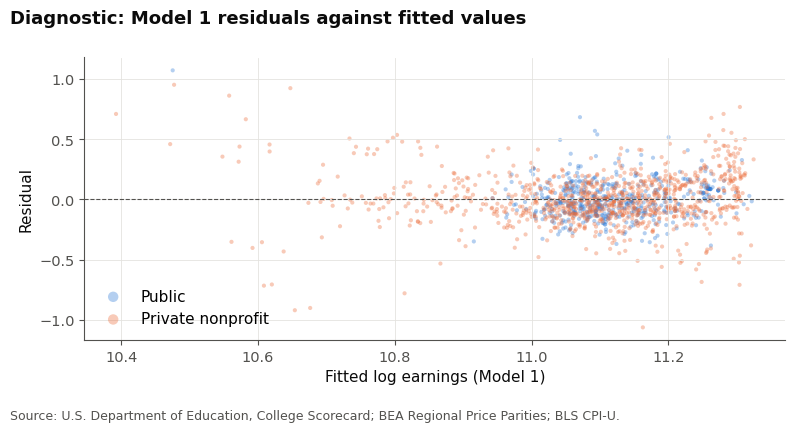

,INSTNM,STABBR,inst_type,tuition_in_real,earn_7yr,cooks_d
1094,United States Merchant Marine Academy,NY,Public,897.258,103324.0,1.144
1599,Brigham Young University,UT,Private nonprofit,6544.699,91851.0,0.104
355,Brigham Young University-Idaho,ID,Private nonprofit,5190.218,66225.0,0.075
1839,Western Governors University,UT,Private nonprofit,8154.944,90964.0,0.065
1822,Embry-Riddle Aeronautical University-Worldwide,FL,Private nonprofit,10412.207,105855.0,0.053


In [17]:
influence = smf.ols("log_earn ~ log_tuition * private", data=main).fit().get_influence()
main["cooks_d"] = influence.cooks_distance[0]
main["resid"] = m1_wide.resid
main["fitted"] = m1_wide.fittedvalues
top_influence = main.nlargest(5, "cooks_d")[["INSTNM", "STABBR", "inst_type", "tuition_in_real", "earn_7yr", "cooks_d"]]
top_influence.round(3).to_csv(RES / "q1_influential_institutions.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
for t in MAIN_TYPES:
    d = main[main["inst_type"] == t]
    ax.scatter(d["fitted"], d["resid"], s=9, alpha=0.35, color=COLORS[t], edgecolors="none", label=t)
ax.axhline(0, color=INK2, lw=0.8, ls="--")
ax.set_xlabel("Fitted log earnings (Model 1)")
ax.set_ylabel("Residual")
ax.legend(loc="lower left", markerscale=2.5)
figure_title(fig, "Diagnostic: Model 1 residuals against fitted values")
footer(fig, SOURCE)
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig(FIG / "diag_q1_residuals.png")
plt.show()
top_influence.round(3)

In [18]:
# Supplementary check: Model 1 without the single most influential institution (kept in the main analysis).
most_influential = main.loc[main["cooks_d"].idxmax()]
without = main.drop(main["cooks_d"].idxmax())
m_wo = fit_state_cluster("log_earn ~ log_tuition * private", without)
q1_influence_check = pd.DataFrame(type_slopes(m_wo, without, f"Model 1 without {most_influential['INSTNM']}", "Wider sample"))
q1_influence_check.to_csv(RES / "q1_influence_check.csv", index=False)
q1_influence_check.assign(slope_95ci=q1_influence_check.apply(fmt_slope, axis=1))[["model", "type", "slope_95ci", "p_value", "n"]].round(4)

,model,type,slope_95ci,p_value,n
0,Model 1 without United States Merchant Marine ...,Public,"0.318 [0.260, 0.376]",0.000,519
1,Model 1 without United States Merchant Marine ...,Private nonprofit,"0.366 [0.268, 0.465]",0.000,953
2,Model 1 without United States Merchant Marine ...,Difference (phi),"0.048 [-0.080, 0.176]",0.459,1472


### Q1 sensitivity checks

All checks keep the same seven-year completion outcome. Each row re-estimates the type-specific tuition slopes under one change.

In [19]:
sens = []
sens += type_slopes(m1_wide, main, "Main: in-state tuition, 2024 dollars", "Wider sample")

alt = main.assign(log_tuition=np.log(main["tuition_out_real"]))
m = fit_state_cluster("log_earn ~ log_tuition * private", alt)
keep_coefs(m, "Out-of-state tuition", "Wider sample")
sens += type_slopes(m, alt, "Out-of-state tuition (same institutions)", "Wider sample")

alt = main.assign(log_tuition=np.log(main["tuition_in_nominal"]))
m = fit_state_cluster("log_earn ~ log_tuition * private", alt)
keep_coefs(m, "Nominal tuition", "Wider sample")
sens += type_slopes(m, alt, "Nominal tuition", "Wider sample")

m = fit_state_cluster("log_earn ~ log_tuition * private + C(STABBR)", main)
keep_coefs(m, "State fixed effects", "Wider sample")
sens += type_slopes(m, main, "State fixed effects", "Wider sample")

nested_frame = model_frame(inst_clean[inst_clean["in_nested_sample"]])
m = fit_state_cluster("log_earn ~ log_tuition * private", nested_frame)
sens += type_slopes(m, nested_frame, "Model 1 on nested-model sample", "Nested sample")

# For-profit institutions added as a third category on the wider sample (no SAT adjustment).
fp_formula = "log_earn ~ log_tuition * C(inst_type, Treatment('Public'))"
m_fp = fit_state_cluster(fp_formula, q1)
keep_coefs(m_fp, "Three institution types", "Q1 sample incl. for-profit")
fp_term = "log_tuition:C(inst_type, Treatment('Public'))[T.{}]"
for t, w in (("Public", {"log_tuition": 1}),
             ("Private nonprofit", {"log_tuition": 1, fp_term.format("Private nonprofit"): 1}),
             ("Private for-profit", {"log_tuition": 1, fp_term.format("Private for-profit"): 1})):
    est, se = combo(m_fp, w)
    sens.append({"type": t, **summarize("Adding 69 for-profit institutions", "Q1 sample incl. for-profit",
                                       est, se, int((q1["inst_type"] == t).sum()))})

q1_sens = pd.DataFrame(sens)
q1_sens["scale"] = "log-log elasticity"

# Level specification: dollars of earnings per $1,000 of tuition.
level = main.assign(tuition_k=main["tuition_in_real"] / 1000)
m_lvl = fit_state_cluster("earn_7yr ~ tuition_k * private", level)
keep_coefs(m_lvl, "Level scale", "Wider sample")
lvl = pd.DataFrame(type_slopes(m_lvl, level, "Level scale (earnings $ per $1,000 tuition)", "Wider sample",
                               slope="tuition_k", inter="tuition_k:private"))
lvl["scale"] = "dollars per $1,000 tuition"
q1_sens = pd.concat([q1_sens, lvl], ignore_index=True)
q1_sens.to_csv(RES / "q1_sensitivity.csv", index=False)
q1_sens.assign(slope_95ci=q1_sens.apply(fmt_slope, axis=1))[["model", "type", "slope_95ci", "p_value", "n", "scale"]].round(4)

,model,type,slope_95ci,p_value,n,scale
0,"Main: in-state tuition, 2024 dollars",Public,"0.261 [0.130, 0.391]",0.0001,520,log-log elasticity
1,"Main: in-state tuition, 2024 dollars",Private nonprofit,"0.366 [0.268, 0.465]",0.0000,953,log-log elasticity
2,"Main: in-state tuition, 2024 dollars",Difference (phi),"0.106 [-0.104, 0.315]",0.3225,1473,log-log elasticity
3,Out-of-state tuition (same institutions),Public,"0.230 [0.092, 0.368]",0.0011,520,log-log elasticity
4,Out-of-state tuition (same institutions),Private nonprofit,"0.366 [0.268, 0.465]",0.0000,953,log-log elasticity
5,Out-of-state tuition (same institutions),Difference (phi),"0.136 [-0.080, 0.353]",0.2173,1473,log-log elasticity
6,Nominal tuition,Public,"0.261 [0.131, 0.391]",0.0001,520,log-log elasticity
7,Nominal tuition,Private nonprofit,"0.366 [0.268, 0.465]",0.0000,953,log-log elasticity
8,Nominal tuition,Difference (phi),"0.105 [-0.104, 0.314]",0.3234,1473,log-log elasticity
9,State fixed effects,Public,"0.262 [0.116, 0.408]",0.0004,520,log-log elasticity


### Figure 1 and Figure 2

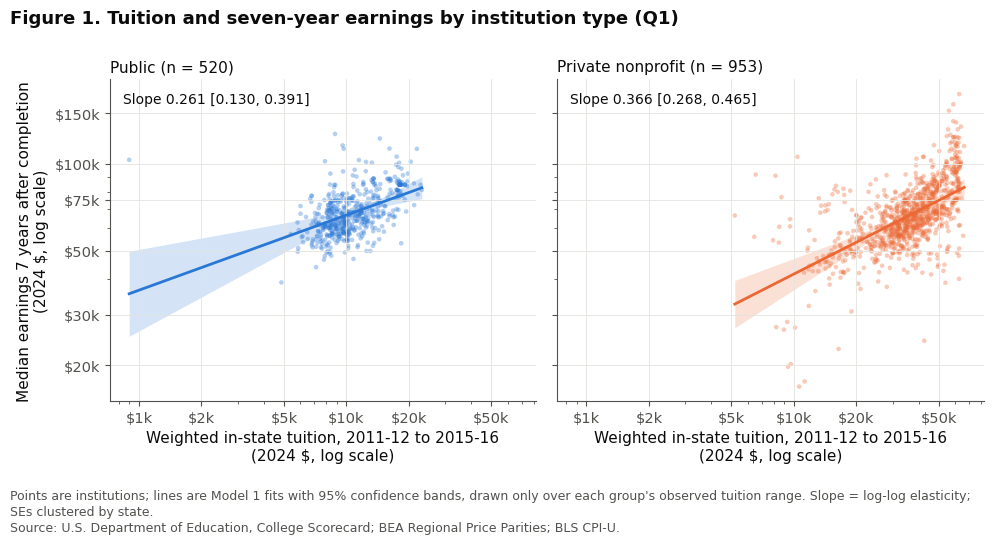

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for ax, t in zip(axes, MAIN_TYPES):
    d = main[main["inst_type"] == t]
    ax.scatter(d["tuition_in_real"], d["earn_7yr"], s=11, alpha=0.35, color=COLORS[t], edgecolors="none")
    grid = np.linspace(d["log_tuition"].min(), d["log_tuition"].max(), 100)
    pred = m1_wide.get_prediction(pd.DataFrame({"log_tuition": grid, "private": int(t != "Public")})).summary_frame(alpha=0.05)
    ax.fill_between(np.exp(grid), np.exp(pred["mean_ci_lower"]), np.exp(pred["mean_ci_upper"]), color=COLORS[t], alpha=0.2, lw=0)
    ax.plot(np.exp(grid), np.exp(pred["mean"]), color=COLORS[t], lw=2)
    row = q1_slopes[q1_slopes["type"] == t].iloc[0]
    ax.text(0.03, 0.96, f"Slope {fmt_slope(row)}", transform=ax.transAxes, va="top", color=INK, fontsize=10)
    ax.set_title(f"{t} (n = {len(d):,})", loc="left", color=INK)
    log_axes(ax, [1000, 2000, 5000, 10000, 20000, 50000], [20000, 30000, 50000, 75000, 100000, 150000])
    ax.set_xlabel("Weighted in-state tuition, 2011-12 to 2015-16\n(2024 $, log scale)")
axes[0].set_ylabel("Median earnings 7 years after completion\n(2024 $, log scale)")
figure_title(fig, "Figure 1. Tuition and seven-year earnings by institution type (Q1)")
footer(fig, "Points are institutions; lines are Model 1 fits with 95% confidence bands, drawn only over each group's observed tuition range. "
            "Slope = log-log elasticity; SEs clustered by state.\n" + SOURCE)
fig.tight_layout(rect=(0, 0, 1, 0.91))
fig.savefig(FIG / "fig1_q1_scatter.png")
plt.show()

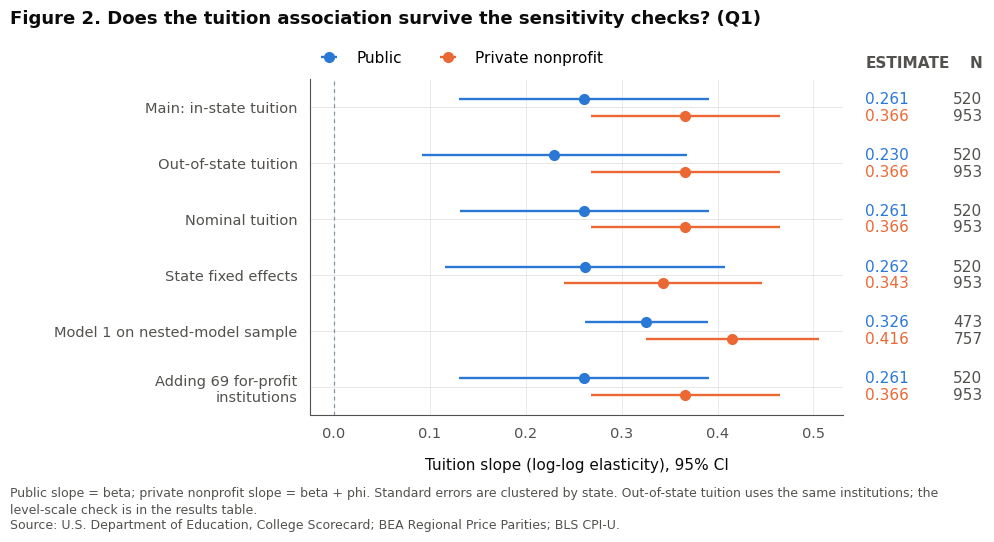

In [21]:
import textwrap


def coefficient_axes(title, labels, x_range, height=5.0):
    """A coefficient panel plus compact estimate and sample-size columns; error bars retain 95% CIs."""
    fig, (ax, values) = plt.subplots(1, 2, figsize=(10, height),
                                    gridspec_kw={"width_ratios": [4.15, 0.95], "wspace": 0.06}, sharey=True)
    fig.subplots_adjust(left=0.31, right=0.985, top=0.84, bottom=0.17)
    figure_title(fig, title)
    y = np.arange(len(labels))
    ax.set_yticks(y, [textwrap.fill(label, 32) for label in labels])
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.set_xlim(*x_range)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.grid(axis="x", color="#e6ebf0", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.axvline(0, color="#87939f", lw=0.9, ls=(0, (3, 3)))
    ax.tick_params(axis="both", length=0, pad=9)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_xlabel("Tuition slope (log-log elasticity), 95% CI", labelpad=12)
    values.set_xlim(0, 1)
    values.axis("off")
    values.text(0.02, 1.035, "ESTIMATE", transform=values.transAxes, color=INK2, fontsize=VALUE_LABEL_SIZE, fontweight="bold")
    values.text(0.98, 1.035, "N", ha="right", transform=values.transAxes, color=INK2, fontsize=VALUE_LABEL_SIZE, fontweight="bold")
    return fig, ax, values


log_rows = q1_sens[(q1_sens["scale"] == "log-log elasticity") & q1_sens["type"].isin(MAIN_TYPES)]
specs = list(dict.fromkeys(log_rows["model"]))
labels = [s.replace(" (same institutions)", "").replace("Main: in-state tuition, 2024 dollars", "Main: in-state tuition") for s in specs]
fig, ax, values = coefficient_axes(
    "Figure 2. Does the tuition association survive the sensitivity checks? (Q1)",
    labels,
    (min(log_rows["ci_low"].min(), 0) - 0.025, log_rows["ci_high"].max() + 0.025), height=5.0)
for i, t in enumerate(MAIN_TYPES):
    d = log_rows[log_rows["type"] == t].set_index("model").loc[specs]
    y = np.arange(len(specs)) + (i - 0.5) * 0.30
    ax.errorbar(d["estimate"], y, xerr=[d["estimate"] - d["ci_low"], d["ci_high"] - d["estimate"]],
                fmt="o", color=COLORS[t], ms=7, lw=1.7, capsize=0, label=t, zorder=3)
    for yi, r in zip(y, d.itertuples()):
        values.text(0.02, yi, f"{r.estimate:.3f}", va="center", color=COLORS[t], fontsize=VALUE_LABEL_SIZE)
        values.text(0.98, yi, f"{r.n:,}", ha="right", va="center", color=INK2, fontsize=VALUE_LABEL_SIZE)
handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper left", bbox_to_anchor=(0.30, 0.925), ncol=2, fontsize=11)
footer(fig, "Public slope = beta; private nonprofit slope = beta + phi. Standard errors are clustered by state. "
            "Out-of-state tuition uses the same institutions; the level-scale check is in the results table.\n" + SOURCE, y=0.025)
fig.savefig(FIG / "fig2_q1_sensitivity.png")
plt.show()

### Q1 interpretation

- **Both sectors show a positive association.** In Model 1 the public slope is 0.261 [0.130, 0.391] and the private nonprofit slope is 0.366 [0.268, 0.465]. Across institutions, a 10% higher tuition goes with about 2.5% (public) and 3.5% (private nonprofit) higher median earnings seven years after completion.
- **The two slopes are not reliably different.** The difference φ is 0.106 [-0.104, 0.315], p = 0.32, so the data do not show that the relationship is steeper in one sector.
- **The result holds across the sensitivity checks.** Out-of-state tuition, nominal tuition, state fixed effects and adding for-profit institutions all leave the slopes positive with confidence intervals above zero. Nominal and 2024-dollar tuition give almost identical slopes because the CPI conversion rescales every institution by nearly the same factor.
- **One institution moves the public slope.** The United States Merchant Marine Academy (public, tuition about USD 900) has a Cook's distance of 1.14. Without it, the public slope is 0.318 [0.260, 0.376]. It stays in the main analysis as a valid but unusual college.
- **The scale changes the comparison.** On the level scale, USD 1,000 more tuition goes with about USD 1,821 more earnings at public institutions and USD 839 at private nonprofit ones. Public tuition is much lower, so the same dollar amount is a larger proportional difference.
- **For-profit institutions are imprecise.** Their slope is 0.148 [-0.114, 0.410] with only 69 institutions.
- **The tuition ranges barely overlap.** Only 139 of 953 private nonprofit institutions fall inside the public tuition range (USD 5,190 to USD 23,132), so the slope comparison mostly contrasts different parts of the tuition distribution.

## 3. Q2 Student background

**Does the relationship remain after accounting for average SAT score and median family income?** Models 1 and 2 are compared on the same nested-model sample.

### Model 2: add SAT and family income

Model 2 retains the tuition, institution-type and interaction terms in Model 1, then adds average SAT and CPI-adjusted median family income:

$$
\begin{aligned}
\log(Earnings_i)={}&\alpha+\beta\log(Tuition_i)+\gamma Private_i\\
&+\varphi\log(Tuition_i)\times Private_i\\
&+\delta\,\frac{SAT_i}{100}+\theta\,\frac{FamilyIncome_i}{10{,}000}+\varepsilon_i.
\end{aligned}
$$

Here $SAT_i$ is the average of Fall 2011 and Fall 2012 SAT scores, and $FamilyIncome_i$ is median family income converted to 2024 dollars. The coefficients $\delta$ and $\theta$ correspond to 100 SAT points and 10,000 dollars of family income, respectively. In the code these variables are `sat100` and `faminc10k`.

- **Public tuition slope after background adjustment:** $\beta$.
- **Private nonprofit tuition slope after background adjustment:** $\beta+\varphi$.
- **The interaction coefficient $\varphi$ tests the tuition-slope difference** after including these background measures. SAT and family income have common coefficients across the two institution types.

Model 1 and Model 2 use the same 1,230 institutions (473 public and 757 private nonprofit), with standard errors clustered by state. Coefficients are re-estimated in each model; using the same symbols does not mean their values are held fixed. The change in tuition slopes describes adjustment on identical observations, not a causal decomposition.


In [22]:
nq = nested_frame
m1_n = fit_state_cluster("log_earn ~ log_tuition * private", nq)
m2_n = fit_state_cluster("log_earn ~ log_tuition * private + sat100 + faminc10k", nq)
keep_coefs(m1_n, "Model 1", "Nested sample")
keep_coefs(m2_n, "Model 2", "Nested sample")
q2 = pd.DataFrame(type_slopes(m1_n, nq, "Model 1", "Nested sample") + type_slopes(m2_n, nq, "Model 2", "Nested sample"))
q2.to_csv(RES / "q2_slopes.csv", index=False)
print(f"Nested sample: {len(nq):,} institutions; R-squared Model 1 = {m1_n.rsquared:.3f}, Model 2 = {m2_n.rsquared:.3f}")
display(q2.assign(slope_95ci=q2.apply(fmt_slope, axis=1))[["model", "type", "slope_95ci", "p_value", "n"]].round(4))
m2_n.params[["sat100", "faminc10k"]].round(4)

Nested sample: 1,230 institutions; R-squared Model 1 = 0.369, Model 2 = 0.478


,model,type,slope_95ci,p_value,n
0,Model 1,Public,"0.326 [0.262, 0.390]",0.0000,473
1,Model 1,Private nonprofit,"0.416 [0.325, 0.506]",0.0000,757
2,Model 1,Difference (phi),"0.090 [-0.031, 0.210]",0.1460,1230
3,Model 2,Public,"0.215 [0.136, 0.294]",0.0000,473
4,Model 2,Private nonprofit,"0.238 [0.154, 0.322]",0.0000,757
5,Model 2,Difference (phi),"0.023 [-0.085, 0.131]",0.6737,1230


sat100       0.0644
faminc10k    0.0039
dtype: float64

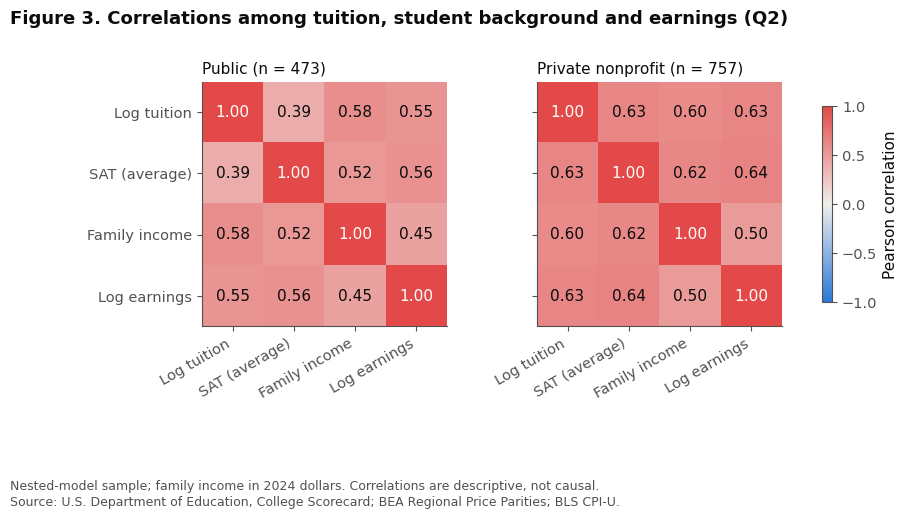

In [23]:
CORR_VARS = {"log_tuition": "Log tuition", "sat_avg": "SAT (average)", "faminc_real": "Family income", "log_earn": "Log earnings"}
corr_tables = {}
for t in MAIN_TYPES:
    c = nq.loc[nq["inst_type"] == t, list(CORR_VARS)].corr()
    c.index = c.columns = list(CORR_VARS.values())
    corr_tables[t] = c
    c.round(3).to_csv(RES / f"q2_correlations_{t.lower().replace(' ', '_')}.csv")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), gridspec_kw={"wspace": 0.06})
for k, (ax, t) in enumerate(zip(axes, MAIN_TYPES)):
    c = corr_tables[t]
    im = ax.imshow(c.values, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(4), c.columns, rotation=30, ha="right")
    ax.set_yticks(range(4), c.index if k == 0 else [""] * 4)
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{c.values[i, j]:.2f}", ha="center", va="center", fontsize=11,
                    color="white" if abs(c.values[i, j]) > 0.85 else INK)
    ax.set_title(f"{t} (n = {(nq['inst_type'] == t).sum():,})", loc="left", color=INK)
fig.subplots_adjust(bottom=0.32, top=0.83)
fig.colorbar(im, ax=axes, shrink=0.8, label="Pearson correlation")
figure_title(fig, "Figure 3. Correlations among tuition, student background and earnings (Q2)")
footer(fig, "Nested-model sample; family income in 2024 dollars. Correlations are descriptive, not causal.\n" + SOURCE, y=0.0)
fig.savefig(FIG / "fig3_q2_correlations.png")
plt.show()

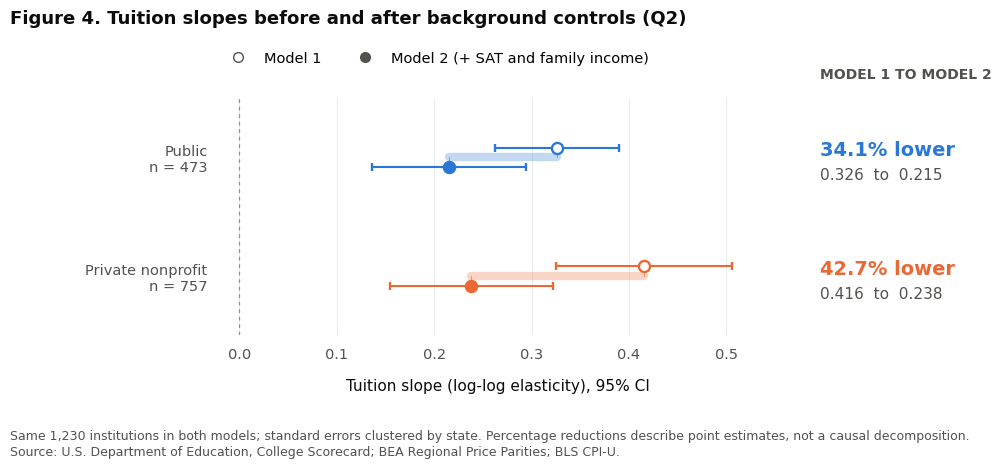

In [24]:
# Q2: a dumbbell emphasizes the before/after coefficient movement while retaining both 95% CIs.
fig, (ax, changes) = plt.subplots(1, 2, figsize=(10, 4.4),
                                 gridspec_kw={"width_ratios": [4, 1.25], "wspace": 0.10}, sharey=True)
fig.subplots_adjust(left=0.22, right=0.985, top=0.78, bottom=0.24)
figure_title(fig, "Figure 4. Tuition slopes before and after background controls (Q2)")
handles = [plt.Line2D([], [], marker="o", color=INK2, mfc="white", ls="", ms=7, label="Model 1"),
           plt.Line2D([], [], marker="o", color=INK2, mfc=INK2, ls="", ms=7, label="Model 2 (+ SAT and family income)")]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.21, 0.915), ncol=2, fontsize=10.5)
for i, t in enumerate(MAIN_TYPES):
    rows = q2[q2["type"] == t].set_index("model").loc[["Model 1", "Model 2"]]
    before, after = rows["estimate"]
    ax.plot([before, after], [i, i], color=COLORS[t], alpha=0.28, linewidth=6, solid_capstyle="round", zorder=1)
    for stage, r in enumerate(rows.itertuples()):
        yy = i + (stage - 0.5) * 0.16
        ax.errorbar(r.estimate, yy, xerr=[[r.estimate-r.ci_low], [r.ci_high-r.estimate]],
                    fmt="o", color=COLORS[t], markerfacecolor="white" if stage == 0 else COLORS[t],
                    markeredgewidth=1.7, ms=8, elinewidth=1.5, capsize=3, zorder=3)
        ax.plot([r.estimate, r.estimate], [i, yy], color=COLORS[t], lw=0.8, alpha=0.5)
    changes.text(0.05, i-0.06, f"{(1-after/before)*100:.1f}% lower", va="center", color=COLORS[t], fontsize=14, fontweight="bold")
    changes.text(0.05, i+0.15, f"{before:.3f}  to  {after:.3f}", va="center", color=INK2, fontsize=11)
ax.set_yticks(range(2), [f"{t}\nn = {int(q2.loc[(q2['type'] == t) & (q2['model'] == 'Model 1'), 'n'].iloc[0]):,}" for t in MAIN_TYPES])
ax.set_ylim(1.5, -0.5)
ax.set_xlim(-0.02, 0.55)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#e6ebf0", linewidth=0.7)
ax.axvline(0, color="#87939f", lw=0.9, ls=(0, (3, 3)))
ax.tick_params(axis="both", length=0, pad=9)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("Tuition slope (log-log elasticity), 95% CI", labelpad=12)
changes.axis("off")
changes.text(0.05, 1.08, "MODEL 1 TO MODEL 2", transform=changes.transAxes, color=INK2, fontsize=10, fontweight="bold")
footer(fig, f"Same {len(nq):,} institutions in both models; standard errors clustered by state. "
            "Percentage reductions describe point estimates, not a causal decomposition.\n" + SOURCE, y=0.025)
fig.savefig(FIG / "fig4_q2_coefficients.png")
plt.show()

### Q2 interpretation

- **Slopes decrease after adjustment.** On the same 1,230 institutions, adding SAT and family income lowers the public slope from 0.326 to 0.215 (about one third) and the private nonprofit slope from 0.416 to 0.238 (about 43%).
- **The association remains after adjustment.** Both Model 2 slopes stay positive with confidence intervals above zero: a 10% tuition difference goes with about 2.1% (public) and 2.3% (private nonprofit) higher earnings.
- **The sector gap shrinks.** The difference φ falls from 0.090 to 0.023 (p = 0.67).
- **SAT is strongly associated with earnings.** Each 100 SAT points goes with about 6.7% higher earnings; the family-income coefficient is small and not statistically significant in Model 2 (p = 0.25).
- **Tuition and intake move together.** Within each sector, log tuition correlates 0.39 to 0.63 with SAT and 0.58 to 0.60 with family income, which supports examining background-adjusted models. SAT and family income are institutional summaries and only partial controls for selection.

## 4. Q3 Regional prices

**Does the tuition-earnings association change after accounting for state price levels?** Model 3 adds log(RPP/100) to Model 2 on the same observations. Dividing earnings by RPP is equivalent to fixing the RPP coefficient λ at 1; the maps show that direct adjustment descriptively.

### Model 3: add state price levels

Model 3 retains all terms in Model 2 and adds the institution state's average RPP for 2022 and 2023:

$$
\begin{aligned}
\log(Earnings_i)={}&\alpha+\beta\log(Tuition_i)+\gamma Private_i\\
&+\varphi\log(Tuition_i)\times Private_i\\
&+\delta\,\frac{SAT_i}{100}+\theta\,\frac{FamilyIncome_i}{10{,}000}\\
&+\lambda\log\!\left(\frac{RPP_i}{100}\right)+\varepsilon_i.
\end{aligned}
$$

The symbols follow the proposal: $\delta$ is the SAT coefficient, $\theta$ the family-income coefficient and $\lambda$ the state-price coefficient. In the code, `log_rpp` is $\log(RPP_i/100)$. The background and state-price coefficients are common across the two institution types.

- **Public tuition slope after background and state-price adjustment:** $\beta$.
- **Private nonprofit tuition slope after these adjustments:** $\beta+\varphi$.
- **The interaction coefficient $\varphi$ tests whether these adjusted tuition slopes differ.**

Models 2 and 3 use the same 1,230 institutions, with standard errors clustered by state; all coefficients are re-estimated. The outcome remains published earnings. The maps separately show direct RPP adjustment ($Earnings_i\times100/RPP_i$); this adjustment is not applied on top of the regression model and no model-predicted earnings are used in the maps.


In [25]:
m3_n = fit_state_cluster("log_earn ~ log_tuition * private + sat100 + faminc10k + log_rpp", nq)
keep_coefs(m3_n, "Model 3", "Nested sample")
q3 = pd.DataFrame(type_slopes(m2_n, nq, "Model 2", "Nested sample") + type_slopes(m3_n, nq, "Model 3", "Nested sample"))
q3.to_csv(RES / "q3_slopes.csv", index=False)
lam = summarize("Model 3", "Nested sample", m3_n.params["log_rpp"], m3_n.bse["log_rpp"], len(nq))
pd.DataFrame([{"term": "log(RPP/100), lambda", **lam}]).to_csv(RES / "q3_rpp_coefficient.csv", index=False)
print(f"lambda = {lam['estimate']:.3f} [{lam['ci_low']:.3f}, {lam['ci_high']:.3f}]; R-squared Model 2 = {m2_n.rsquared:.3f}, Model 3 = {m3_n.rsquared:.3f}")
q3.assign(slope_95ci=q3.apply(fmt_slope, axis=1))[["model", "type", "slope_95ci", "p_value", "n"]].round(4)

lambda = 0.768 [0.615, 0.921]; R-squared Model 2 = 0.478, Model 3 = 0.544


,model,type,slope_95ci,p_value,n
0,Model 2,Public,"0.215 [0.136, 0.294]",0.0000,473
1,Model 2,Private nonprofit,"0.238 [0.154, 0.322]",0.0000,757
2,Model 2,Difference (phi),"0.023 [-0.085, 0.131]",0.6737,1230
3,Model 3,Public,"0.153 [0.054, 0.252]",0.0024,473
4,Model 3,Private nonprofit,"0.166 [0.096, 0.237]",0.0000,757
5,Model 3,Difference (phi),"0.013 [-0.073, 0.099]",0.7641,1230


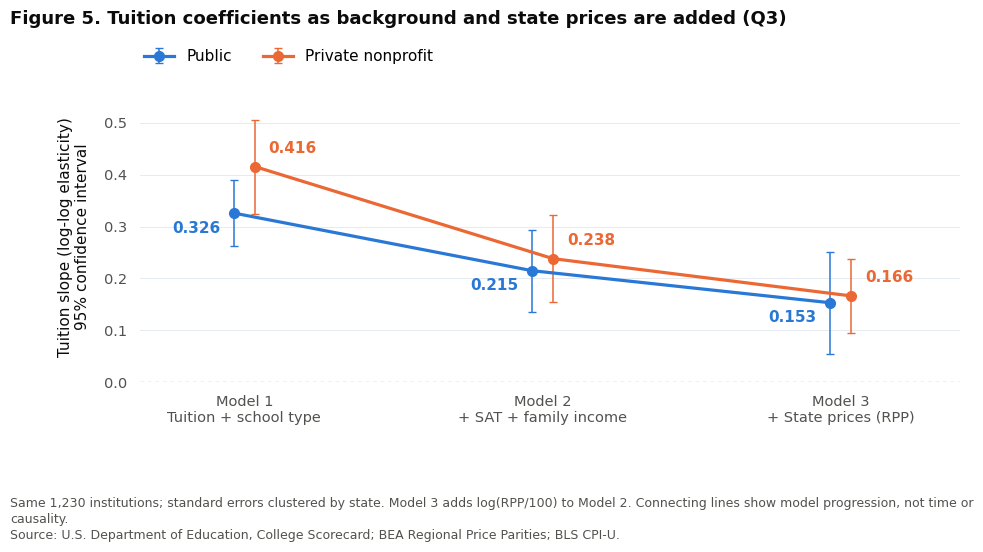

In [26]:
# Q3: show the complete specification path on the same nested sample, not a time series.
path_rows = pd.concat([q2, q3[q3["model"] == "Model 3"]], ignore_index=True)
models = ["Model 1", "Model 2", "Model 3"]
fig, ax = plt.subplots(figsize=(10, 5.1))
fig.subplots_adjust(left=0.14, right=0.96, top=0.82, bottom=0.25)
figure_title(fig, "Figure 5. Tuition coefficients as background and state prices are added (Q3)")
for i, t in enumerate(MAIN_TYPES):
    d = path_rows[path_rows["type"] == t].set_index("model").loc[models]
    x = np.arange(3) + (i - 0.5) * 0.07
    ax.errorbar(x, d["estimate"], yerr=[d["estimate"]-d["ci_low"], d["ci_high"]-d["estimate"]],
                fmt="o-", color=COLORS[t], lw=2.3, ms=7, elinewidth=1.1, capsize=3, label=t, zorder=3)
    for xx, r in zip(x, d.itertuples()):
        ax.annotate(f"{r.estimate:.3f}", (xx, r.estimate), xytext=(-10, -14) if i == 0 else (10, 10),
                    textcoords="offset points", ha="right" if i == 0 else "left", color=COLORS[t], fontsize=11, fontweight="bold")
ax.set_xticks(range(3), ["Model 1\nTuition + school type", "Model 2\n+ SAT + family income", "Model 3\n+ State prices (RPP)"])
ax.set_xlim(-0.35, 2.4)
ax.set_ylim(0, 0.56)
ax.set_ylabel("Tuition slope (log-log elasticity)\n95% confidence interval", labelpad=10)
ax.tick_params(axis="both", length=0, pad=9)
ax.set_axisbelow(True)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#e6ebf0", linewidth=0.7)
ax.axhline(0, color="#87939f", lw=0.9, ls=(0, (3, 3)))
for spine in ax.spines.values():
    spine.set_visible(False)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.13, 0.93), ncol=2, fontsize=11)
footer(fig, f"Same {len(nq):,} institutions; standard errors clustered by state. Model 3 adds log(RPP/100) to Model 2. "
            "Connecting lines show model progression, not time or causality.\n" + SOURCE, y=0.025)
fig.savefig(FIG / "fig5_q3_coefficients.png")
plt.show()

In [27]:
MIN_INSTITUTIONS = 5
state_stats = (nq.groupby(["STABBR", "inst_type"])
               .agg(institutions=("UNITID", "size"), median_published=("earn_7yr", "median"),
                    median_rpp_adjusted=("earn_rpp_adjusted", "median"))
               .reset_index())
state_stats["shown_on_map"] = state_stats["institutions"] >= MIN_INSTITUTIONS
state_stats.to_csv(RES / "q3_state_medians.csv", index=False)
coverage = state_stats.pivot(index="STABBR", columns="inst_type", values="institutions").reindex(sorted(STATE_CODES)).fillna(0)
for t in MAIN_TYPES:
    print(f"{t}: {(coverage[t] >= MIN_INSTITUTIONS).sum()} of 51 states/DC have at least {MIN_INSTITUTIONS} institutions")
shown = state_stats[state_stats["shown_on_map"]].copy()
shown["rank_published"] = shown.groupby("inst_type")["median_published"].rank(ascending=False).astype(int)
shown["rank_adjusted"] = shown.groupby("inst_type")["median_rpp_adjusted"].rank(ascending=False).astype(int)
shown["rank_change"] = shown["rank_published"] - shown["rank_adjusted"]
shown = shown.merge(state_rpp[["STABBR", "rpp_avg"]], on="STABBR")
print("Largest rank changes after RPP adjustment (positive = moves up):")
pd.concat([shown.sort_values("rank_change").groupby("inst_type").head(3),
           shown.sort_values("rank_change", ascending=False).groupby("inst_type").head(3)]
          ).sort_values(["inst_type", "rank_change"])[["inst_type", "STABBR", "rpp_avg", "institutions", "median_published",
                                                       "median_rpp_adjusted", "rank_published", "rank_adjusted", "rank_change"]].round(1)

Public: 34 of 51 states/DC have at least 5 institutions
Private nonprofit: 37 of 51 states/DC have at least 5 institutions
Largest rank changes after RPP adjustment (positive = moves up):


,inst_type,STABBR,rpp_avg,institutions,median_published,median_rpp_adjusted,rank_published,rank_adjusted,rank_change
42,Private nonprofit,NJ,108.8,13,69600.0,63941.2,10,28,-18
4,Private nonprofit,CA,112.4,48,77628.5,69068.8,7,21,-14
50,Private nonprofit,OR,105.7,10,66930.5,63314.0,17,29,-12
41,Private nonprofit,NE,90.1,12,68148.0,75664.5,15,5,10
14,Private nonprofit,IA,88.6,23,63746.0,71980.6,23,12,11
57,Private nonprofit,SD,88.0,5,63787.0,72485.2,22,9,13
26,Public,MA,108.6,13,69133.0,63685.9,9,29,-20
43,Public,NJ,108.8,12,72711.5,66799.7,5,19,-14
6,Public,CO,102.1,12,63578.0,62295.9,19,33,-14
1,Public,AL,88.6,13,59842.0,67573.0,26,15,11


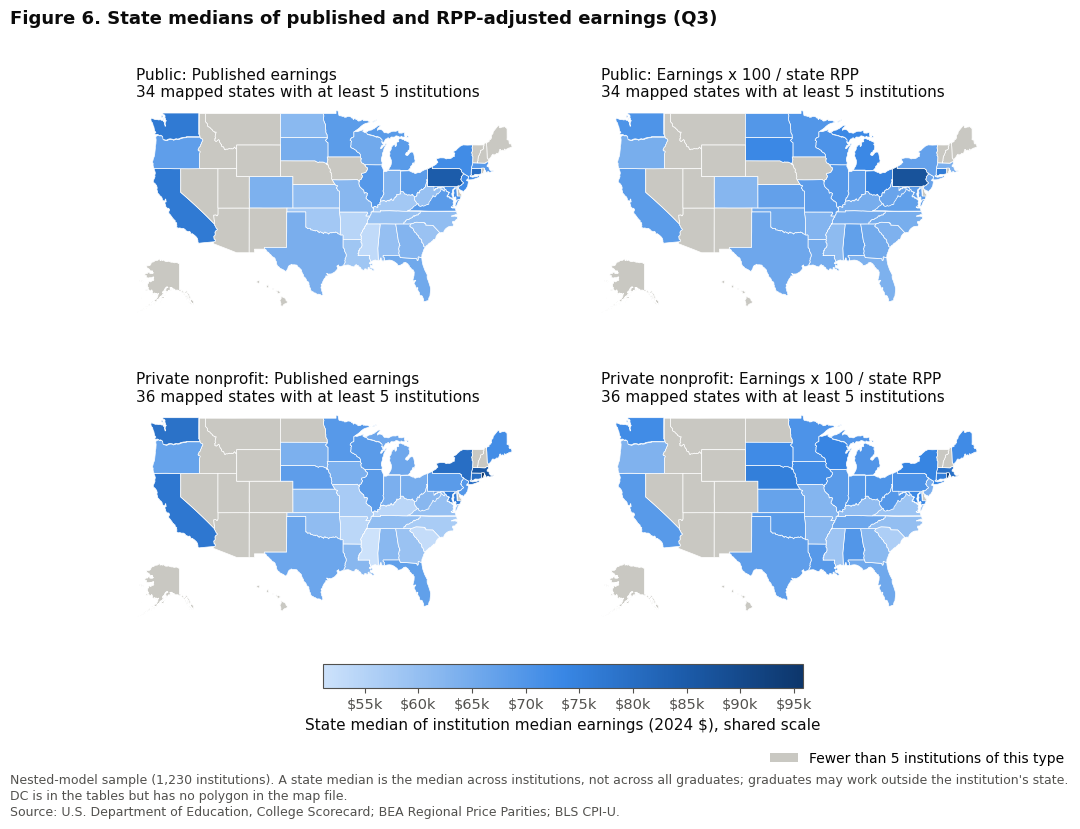

In [28]:
geo = json.loads((RAW / "us-states.json").read_text(encoding="utf-8"))
LAT0 = np.cos(np.radians(37.5))


def project(abbr, lon, lat):
    lon = np.where(lon > 0, lon - 360, lon)
    if abbr == "AK":
        return -122 * LAT0 + (lon + 150) * 0.35 * np.cos(np.radians(62)), 26.5 + (lat - 60) * 0.35
    if abbr == "HI":
        return -105 * LAT0 + (lon + 157) * LAT0, 26 + (lat - 20.5)
    return lon * LAT0, lat


def state_patches(feature):
    g = feature["geometry"]
    polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
    out = []
    for poly in polys:
        ring = np.array(poly[0])
        x, y = project(feature["id"], ring[:, 0], ring[:, 1])
        out.append(Polygon(np.column_stack([x, y]), closed=True))
    return out


values = state_stats[state_stats["shown_on_map"]]
norm_all = Normalize(values[["median_published", "median_rpp_adjusted"]].min().min(),
                     values[["median_published", "median_rpp_adjusted"]].max().max())
fig, axes = plt.subplots(2, 2, figsize=(11, 7.8))
for r, t in enumerate(MAIN_TYPES):
    lookup = state_stats[state_stats["inst_type"] == t].set_index("STABBR")
    for c, (col, label) in enumerate((("median_published", "Published earnings"),
                                      ("median_rpp_adjusted", "Earnings x 100 / state RPP"))):
        ax = axes[r, c]
        for feature in geo["features"]:
            abbr = feature["id"]
            ok = abbr in lookup.index and lookup.loc[abbr, "shown_on_map"]
            color = SEQ_BLUE(norm_all(lookup.loc[abbr, col])) if ok else NODATA
            ax.add_collection(PatchCollection(state_patches(feature), facecolor=color, edgecolor="white", linewidth=0.5))
        ax.set_xlim(-127 * LAT0, -65 * LAT0)
        ax.set_ylim(20, 50)
        ax.set_aspect("equal")
        ax.axis("off")
        mapped_ids = {feature["id"] for feature in geo["features"]}
        shown = int((lookup["shown_on_map"] & lookup.index.isin(mapped_ids)).sum())
        ax.set_title(f"{t}: {label}\n{shown} mapped states with at least {MIN_INSTITUTIONS} institutions", loc="left", fontsize=11, color=INK)
sm = plt.cm.ScalarMappable(norm=norm_all, cmap=SEQ_BLUE)
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.04, pad=0.03, format=dollars)
cbar.set_label("State median of institution median earnings (2024 $), shared scale")
fig.legend(handles=[Patch(facecolor=NODATA, label=f"Fewer than {MIN_INSTITUTIONS} institutions of this type")],
           loc="lower right", bbox_to_anchor=(0.98, -0.005), fontsize=10)
figure_title(fig, "Figure 6. State medians of published and RPP-adjusted earnings (Q3)")
footer(fig, f"Nested-model sample ({len(nq):,} institutions). A state median is the median across institutions, not across all graduates; "
            "graduates may work outside the institution's state. DC is in the tables but has no polygon in the map file.\n" + SOURCE, y=0.0)
fig.savefig(FIG / "fig6_q3_maps.png")
plt.show()

### Q3 interpretation

- **Accounting for state price levels lowers the slopes further.** From Model 2 to Model 3 the public slope falls from 0.215 to 0.153 [0.054, 0.252] and the private nonprofit slope from 0.238 to 0.166 [0.096, 0.237], about 30% each. Both remain positive.
- **The estimated association with state prices is less than proportional.** The RPP coefficient λ is 0.768 [0.615, 0.921]. Because the interval excludes 1, dividing earnings by RPP (which assumes λ = 1) adjusts slightly more than the estimated relationship implies.
- **The maps show where adjustment matters.** High-price states move down the ranking after adjustment (for example New Jersey, California and Massachusetts), while lower-price states move up (for example Nebraska, Iowa and the Dakotas).
- **Coverage limits the maps.** There are 34 eligible public state groups and 37 eligible private nonprofit state/DC groups with at least five institutions. The supplied boundary file displays 34 public and 36 private nonprofit states; DC is retained in the tables but is not drawn. Other mapped states are grey. The institution's state is only a proxy for where graduates work.

## 5. Q4 Field of study

**Within selected bachelor's fields, is higher institutional tuition associated with higher field-specific earnings, and how does the association vary by field?**

Select eight common fields by combined reporting institutions after requiring at least 30 institutions in each sector (ties by CIP code). A separate pooled log-log model is fitted for each field (eight models, yielding 16 type-specific tuition slopes), with heteroskedasticity-robust (HC1) standard errors. SAT and family income are not included.

For institution $i$ in field $f$, use the same parameter notation as the proposal's institution-level models:

$$
\begin{aligned}
\log(Earnings_{if})={}&\alpha_f+\beta_f\log(Tuition_i)+\gamma_f Private_i\\
&+\varphi_f\log(Tuition_i)\times Private_i+\varepsilon_{if}.
\end{aligned}
$$

Here $Private_i=1$ for private nonprofit institutions and $Private_i=0$ for public institutions. The field subscript $f$ indicates that each field has its own coefficients.

- **Public tuition slope:** $\beta_f$; intercept $\alpha_f$.
- **Private nonprofit tuition slope:** $\beta_f+\varphi_f$; intercept $\alpha_f+\gamma_f$.
- **The interaction coefficient $\varphi_f$ tests whether the public and private nonprofit slopes differ:** $H_0:\varphi_f=0$.
- For the private slope, $\mathrm{Var}(\hat\beta_f+\hat\varphi_f)=\mathrm{Var}(\hat\beta_f)+\mathrm{Var}(\hat\varphi_f)+2\mathrm{Cov}(\hat\beta_f,\hat\varphi_f)$, using HC1 covariance.

This is the field-specific counterpart of Model 1, with the same roles for $\alpha$, $\beta$, $\gamma$ and $\varphi$. In the proposal, $\delta$ denotes the SAT coefficient, $\theta$ the family-income coefficient and $\lambda$ the RPP coefficient; these controls are not included in Q4. Only notation is aligned here; the fitted specification and numerical estimates are unchanged.

Figure 8 compares both type-specific tuition slopes within each common field, with 95% confidence intervals and group sample sizes. Each trend line in Figure 7 covers only the tuition range observed in its panel. Limited public-private tuition overlap remains a limitation. Within-field interaction tests are exploratory, with unadjusted p-values across eight fields; cross-field differences require separate tests. All slopes describe associations, not causal returns.

In [29]:
from IPython.display import display

fq = field[field["top8_field"]].copy()
fq["log_earn"] = np.log(fq["earn_7yr_field"])
fq["log_tuition"] = np.log(fq["tuition_in_real"])
fq["private"] = (fq["inst_type"] == "Private nonprofit").astype(int)
FIELD_ORDER = top8_table["cip4"].tolist()
Q4_FORMULA = "log_earn ~ log_tuition + private + log_tuition:private"

q4_rows, q4_difference_rows, q4_coefficient_rows, q4_models = [], [], [], {}
for rank, f in enumerate(FIELD_ORDER, start=1):
    d_f = fq[fq["cip4"] == f]
    m = smf.ols(Q4_FORMULA, data=d_f).fit(cov_type="HC1")
    q4_models[f] = m
    keep_coefs(m, f"Q4 Field {f}", "Main field sample, pooled sectors")
    counts = d_f["inst_type"].value_counts()
    pub_range = d_f.loc[d_f["private"] == 0, "tuition_in_real"]
    npv_range = d_f.loc[d_f["private"] == 1, "tuition_in_real"]
    lo, hi = max(pub_range.min(), npv_range.min()), min(pub_range.max(), npv_range.max())
    if lo > hi:
        lo = hi = np.nan
    for t in MAIN_TYPES:
        d = d_f[d_f["inst_type"] == t]
        weights = {"log_tuition": 1}
        intercept = m.params["Intercept"]
        if t == "Private nonprofit":
            weights["log_tuition:private"] = 1
            intercept += m.params["private"]
        est, se = combo(m, weights)
        row = summarize(f"Q4 Field {f}", "Main field sample, pooled sectors", est, se, len(d))
        q4_rows.append({"cip4": f, "field_name": FIELD_NAMES[f], "type": t, "common_field_rank": rank, **row,
                        "intercept": intercept, "n_model": len(d_f),
                        "tuition_min": d["tuition_in_real"].min(), "tuition_max": d["tuition_in_real"].max(),
                        "shared_range_low": lo, "shared_range_high": hi,
                        "in_shared_range": int(d["tuition_in_real"].between(lo, hi).sum()) if pd.notna(lo) else 0})
    difference = summarize(f"Q4 Field {f}", "Main field sample, pooled sectors",
                           m.params["log_tuition:private"], m.bse["log_tuition:private"], len(d_f))
    q4_difference_rows.append({"cip4": f, "field_name": FIELD_NAMES[f], "common_field_rank": rank,
                               "public_n": int(counts["Public"]), "private_nonprofit_n": int(counts["Private nonprofit"]),
                               **difference})
    for term in m.params.index:
        q4_coefficient_rows.append({"cip4": f, "field_name": FIELD_NAMES[f], "common_field_rank": rank,
                                    "term": term, **summarize(f"Q4 Field {f}", "Main field sample, pooled sectors",
                                                             m.params[term], m.bse[term], len(d_f))})
q4 = pd.DataFrame(q4_rows).drop(columns=["model", "sample"])
q4_differences = pd.DataFrame(q4_difference_rows)
q4_coefficients = pd.DataFrame(q4_coefficient_rows)
q4.to_csv(RES / "q4_field_slopes.csv", index=False)
q4_differences.to_csv(RES / "q4_slope_differences.csv", index=False)
q4_coefficients.to_csv(RES / "q4_model_coefficients.csv", index=False)
print("Eight pooled interaction models; public slope = beta, private nonprofit slope = beta + phi.")
display(q4.assign(slope_95ci=q4.apply(fmt_slope, axis=1))[
    ["common_field_rank", "cip4", "field_name", "type", "slope_95ci", "p_value", "n", "n_model"]].round(4))
print("Within-field slope difference: private nonprofit minus public (phi); unadjusted p-values.")
display(q4_differences.assign(difference_95ci=q4_differences.apply(fmt_slope, axis=1))[
    ["cip4", "field_name", "difference_95ci", "p_value", "public_n", "private_nonprofit_n"]].round(4))

Eight pooled interaction models; public slope = beta, private nonprofit slope = beta + phi.


,common_field_rank,cip4,field_name,type,slope_95ci,p_value,n,n_model
0,1,42.01,"Psychology, General",Public,"0.214 [0.175, 0.253]",0.000,452,1005
1,1,42.01,"Psychology, General",Private nonprofit,"0.312 [0.238, 0.387]",0.000,553,1005
2,2,52.02,"Business Administration, Management and Operat...",Public,"0.422 [0.357, 0.487]",0.000,412,937
3,2,52.02,"Business Administration, Management and Operat...",Private nonprofit,"0.346 [0.241, 0.452]",0.000,525,937
4,3,26.01,"Biology, General",Public,"0.199 [0.160, 0.239]",0.000,432,879
5,3,26.01,"Biology, General",Private nonprofit,"0.258 [0.193, 0.323]",0.000,447,879
6,4,51.38,"Registered Nursing, Nursing Administration, Nu...",Public,"0.008 [-0.035, 0.051]",0.714,342,693
7,4,51.38,"Registered Nursing, Nursing Administration, Nu...",Private nonprofit,"0.145 [0.089, 0.200]",0.000,351,693
8,5,52.03,Accounting and Related Services,Public,"0.375 [0.315, 0.436]",0.000,334,627
9,5,52.03,Accounting and Related Services,Private nonprofit,"0.319 [0.179, 0.460]",0.000,293,627


Within-field slope difference: private nonprofit minus public (phi); unadjusted p-values.


,cip4,field_name,difference_95ci,p_value,public_n,private_nonprofit_n
0,42.01,"Psychology, General","0.098 [0.014, 0.182]",0.0217,452,553
1,52.02,"Business Administration, Management and Operat...","-0.076 [-0.200, 0.048]",0.2320,412,525
2,26.01,"Biology, General","0.059 [-0.017, 0.135]",0.1281,432,447
3,51.38,"Registered Nursing, Nursing Administration, Nu...","0.136 [0.066, 0.207]",0.0001,342,351
4,52.03,Accounting and Related Services,"-0.056 [-0.209, 0.097]",0.4742,334,293
5,13.12,Teacher Education and Professional Development...,"0.175 [0.085, 0.264]",0.0001,326,295
6,09.01,Communication and Media Studies,"0.217 [0.038, 0.396]",0.0174,321,259
7,23.01,"English Language and Literature, General","0.132 [-0.014, 0.277]",0.0765,340,224


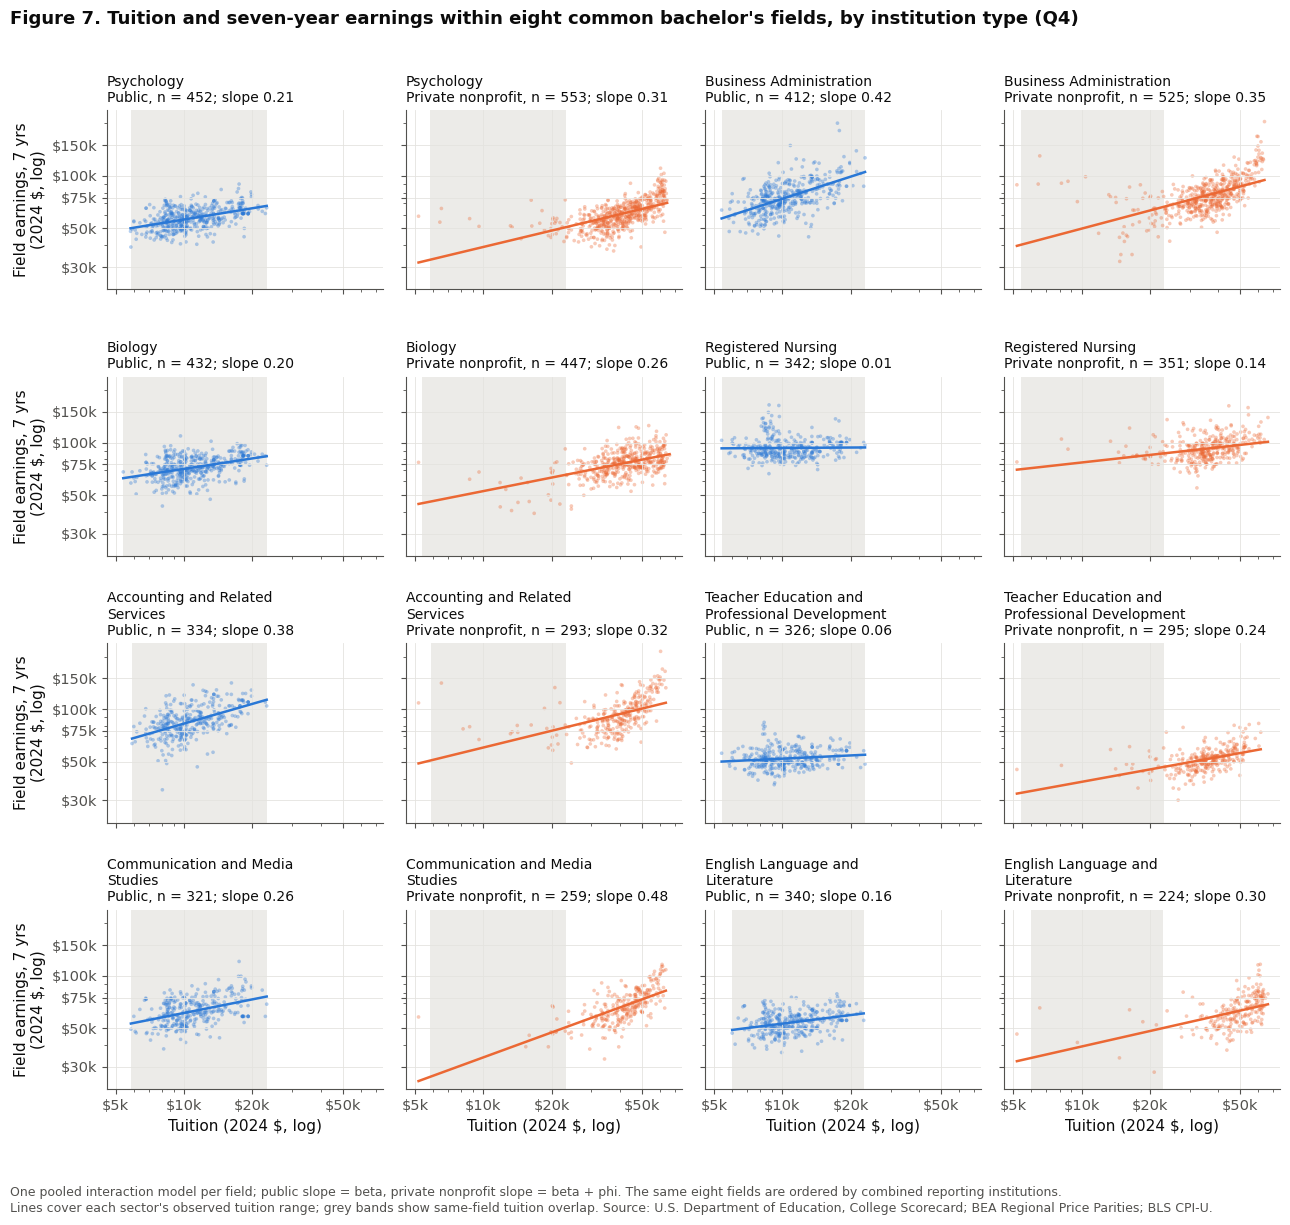

In [30]:
def short(name, width=34):
    name = name.split(",")[0]
    return name if len(name) <= width else name[: width - 1] + "..."


fig, axes = plt.subplots(4, 4, figsize=(13, 12), sharex=True, sharey=True)
for k, f in enumerate(FIELD_ORDER):
    for j, t in enumerate(MAIN_TYPES):
        ax = axes[k // 2, (k % 2) * 2 + j]
        d = fq[(fq["cip4"] == f) & (fq["inst_type"] == t)]
        r = q4[(q4["cip4"] == f) & (q4["type"] == t)].iloc[0]
        if pd.notna(r["shared_range_low"]):
            ax.axvspan(r["shared_range_low"], r["shared_range_high"], color=GRID, alpha=0.7, lw=0)
        ax.scatter(d["tuition_in_real"], d["earn_7yr_field"], s=7, alpha=0.35, color=COLORS[t], edgecolors="none")
        grid = np.linspace(d["log_tuition"].min(), d["log_tuition"].max(), 50)
        ax.plot(np.exp(grid), np.exp(r["intercept"] + r["estimate"] * grid), color=COLORS[t], lw=1.8)
        ax.set_title(f"{textwrap.fill(FIELD_NAMES[f].split(chr(44))[0], 27)}\n{t}, n = {len(d)}; slope {r['estimate']:.2f}", loc="left", fontsize=10, color=INK)
        log_axes(ax, [5000, 10000, 20000, 50000], [30000, 50000, 75000, 100000, 150000])
for ax in axes[-1]:
    ax.set_xlabel("Tuition (2024 $, log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Field earnings, 7 yrs\n(2024 $, log)")
figure_title(fig, "Figure 7. Tuition and seven-year earnings within eight common bachelor's fields, by institution type (Q4)")
footer(fig, "One pooled interaction model per field; public slope = beta, private nonprofit slope = beta + phi. "
            "The same eight fields are ordered by combined reporting institutions.\nLines cover each sector's observed tuition range; grey bands show same-field tuition overlap. " + SOURCE, y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.94), h_pad=2.0)
fig.savefig(FIG / "fig7_q4_field_panels.png")
plt.show()

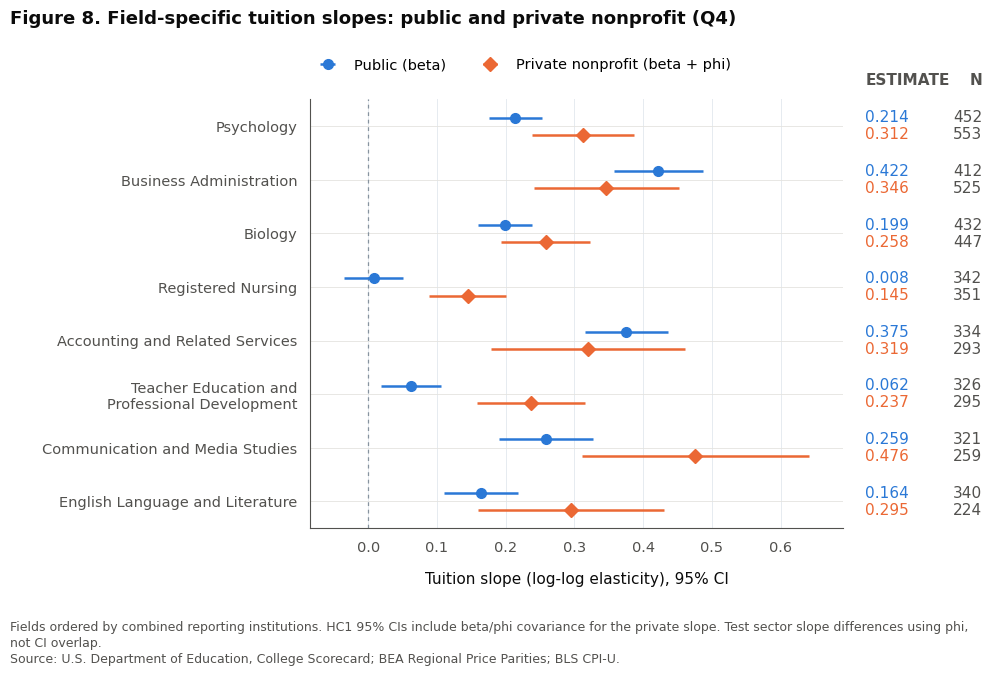

In [31]:
# Figure 8 compares both sector slopes within each of the same eight fields.
x_range = (min(q4["ci_low"].min(), 0) - 0.05, q4["ci_high"].max() + 0.05)
labels = [FIELD_NAMES[f].split(",")[0] for f in FIELD_ORDER]
fig, ax, values = coefficient_axes(
    "Figure 8. Field-specific tuition slopes: public and private nonprofit (Q4)",
    labels, x_range, height=6.4)
for i, t in enumerate(MAIN_TYPES):
    d = q4[q4["type"] == t].set_index("cip4").loc[FIELD_ORDER]
    y = np.arange(len(FIELD_ORDER)) + (i-0.5)*0.32
    slope_label = "beta" if t == "Public" else "beta + phi"
    ax.errorbar(d["estimate"], y, xerr=[d["estimate"]-d["ci_low"], d["ci_high"]-d["estimate"]],
                fmt="o" if t == "Public" else "D", color=COLORS[t], ms=7, lw=1.8, capsize=0,
                label=f"{t} ({slope_label})", zorder=3)
    for yi, r in zip(y, d.itertuples()):
        values.text(0.02, yi, f"{r.estimate:.3f}", va="center", fontsize=VALUE_LABEL_SIZE, color=COLORS[t])
        values.text(0.98, yi, f"{r.n:,}", va="center", ha="right", fontsize=VALUE_LABEL_SIZE, color=INK2)
handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper left", bbox_to_anchor=(0.30, 0.925), ncol=2, fontsize=10.5)
footer(fig, "Fields ordered by combined reporting institutions. HC1 95% CIs include beta/phi covariance for the private slope. "
            "Test sector slope differences using phi, not CI overlap.\n" + SOURCE, y=0.025)
fig.savefig(FIG / "fig8_q4_coefficients.png")
plt.show()

In [32]:
model_coefficients = pd.concat(ALL_COEFS, ignore_index=True)
model_coefficients.to_csv(RES / "model_coefficients.csv", index=False)
print(f"Saved {len(model_coefficients)} coefficient rows; figures: {sorted(p.name for p in FIG.glob('*.png'))}")

Saved 75 coefficient rows; figures: ['diag_q1_residuals.png', 'fig1_q1_scatter.png', 'fig2_q1_sensitivity.png', 'fig3_q2_correlations.png', 'fig4_q2_coefficients.png', 'fig5_q3_coefficients.png', 'fig6_q3_maps.png', 'fig7_q4_field_panels.png', 'fig8_q4_coefficients.png']


### Q4 interpretation

- **Use the same fields for both sectors.** Select eight common fields by combined reporting institutions after requiring at least 30 in each sector. Figure 7 has 16 sector panels, estimated from eight pooled interaction models.
- **Read the paired estimates in Figure 8 as sector slopes.** Blue circles show public slopes ($\beta_f$); orange diamonds show private nonprofit slopes ($\beta_f+\varphi_f$), with HC1 confidence intervals computed from the full covariance matrix.
- **Test sector differences directly.** The preceding difference table reports $\varphi_f$, its confidence interval and unadjusted p-value. Different significance levels or overlapping confidence intervals in the paired slope intervals are not a test of the slope difference. Eight within-field tests are exploratory; comparisons across fields require separate tests.
- **The association is positive in most fields.** Public nursing is close to flat. Differences in slope do not establish a causal effect of tuition or identify why outcomes differ.
- **Limited common support remains.** Grey bands show same-field tuition overlap. A shared field list does not remove the limited overlap between sectors' tuition ranges.
- **Tuition is an institution-level proxy.** Program-level tuition is unavailable, and suppression removes many smaller programs; results describe associations among reporting programs.

## 6. Summary of findings

In [33]:
def get(table, model, t):
    return table[(table["model"] == model) & (table["type"] == t)].iloc[0]


lines = []
for t in MAIN_TYPES:
    lines.append(f"Q1 {t}: slope {fmt_slope(get(q1_slopes, 'Model 1', t))}")
lines.append(f"Q1 difference (phi): {fmt_slope(get(q1_slopes, 'Model 1', 'Difference (phi)'))}, p = {get(q1_slopes, 'Model 1', 'Difference (phi)')['p_value']:.3f}")
for mdl in ("Model 1", "Model 2"):
    for t in MAIN_TYPES:
        lines.append(f"Q2 {mdl} {t}: {fmt_slope(get(q2, mdl, t))}")
for t in MAIN_TYPES:
    lines.append(f"Q3 Model 3 {t}: {fmt_slope(get(q3, 'Model 3', t))}")
lines.append(f"Q3 lambda: {lam['estimate']:.3f} [{lam['ci_low']:.3f}, {lam['ci_high']:.3f}]")
print("\n".join(lines))

# Keep the report aligned with the common-field interaction models.
summary_path = RES / "findings_summary.md"
summary_text = summary_path.read_text(encoding="utf-8")
sample_start = summary_text.index("Q4 uses ")
sample_end = summary_text.index("\n\n", sample_start)
summary_text = (summary_text[:sample_start]
                + f"Q4 uses {len(field):,} bachelor's program records from {field['UNITID'].nunique():,} institutions. "
                + f"{len(ranked)} fields have at least {MIN_FIELD_PER_TYPE} reporting institutions in each sector. "
                + "Rank these common fields by combined reporting institutions (ties by CIP code) and select eight. "
                + "Eight pooled interaction models yield 16 sector slopes. Graduate counts do not determine the ranking."
                + summary_text[sample_end:])
q4_lines = ["## Q4 Field of study (8 common fields; 8 interaction models, 16 sector slopes)", "",
             "For each field: log(earnings) = alpha + beta log(tuition) + gamma Private + phi log(tuition) x Private + error.",
             "Public slope = beta; private nonprofit slope = beta + phi. Confidence intervals use HC1 covariance, including the beta/phi covariance for the private slope.", ""]
for t in MAIN_TYPES:
    q4_lines += [f"### {t}", "", "| Common rank | Field | Institutions | Tuition slope [95% CI] |",
                 "|---:|---|---:|---|"]
    for r in q4[q4["type"] == t].sort_values("common_field_rank").itertuples():
        q4_lines.append(f"| {r.common_field_rank} | {r.field_name} | {r.n} | "
                        f"{r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}] |")
    q4_lines.append("")
q4_lines += ["### Within-field slope differences (private nonprofit minus public)", "",
             "| Field | Phi [95% CI] | Unadjusted p-value |", "|---|---|---:|"]
for r in q4_differences.sort_values("common_field_rank").itertuples():
    q4_lines.append(f"| {r.field_name} | {r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}] | {r.p_value:.4f} |")
n_positive = int((q4["ci_low"] > 0).sum())
q4_lines += ["", f"- {n_positive} of {len(q4)} sector slopes have confidence intervals above zero; public nursing is close to flat.",
             "- The same fields and combined-coverage order are used in both sectors. Figure 7 has 16 panels; Figure 8 pairs the public and private nonprofit slopes within each field on one x-axis scale.",
             "- Phi directly tests the within-field sector slope difference. The eight tests have unadjusted p-values and are exploratory; cross-field comparisons require separate tests.",
             "- Grey bands describe same-field tuition overlap. Limited common support and observational data prevent a causal interpretation.", ""]
start = summary_text.index("## Q4 Field of study")
end = summary_text.index("## Limits to state with the results", start)
summary_text = summary_text[:start] + "\n".join(q4_lines) + "\n" + summary_text[end:]
summary_text = summary_text.replace(
    "Comparisons between fields or sectors are descriptive. Different significance levels do not by themselves establish a difference; formal cross-model comparisons and multiple testing require separate consideration.",
    "Q4 interaction terms directly test within-field sector slope differences, with exploratory unadjusted p-values across eight fields. Different significance levels alone do not establish a slope difference. Cross-field comparisons and multiple testing require separate consideration.")
summary_path.write_text(summary_text, encoding="utf-8")

Q1 Public: slope 0.261 [0.130, 0.391]
Q1 Private nonprofit: slope 0.366 [0.268, 0.465]
Q1 difference (phi): 0.106 [-0.104, 0.315], p = 0.322
Q2 Model 1 Public: 0.326 [0.262, 0.390]
Q2 Model 1 Private nonprofit: 0.416 [0.325, 0.506]
Q2 Model 2 Public: 0.215 [0.136, 0.294]
Q2 Model 2 Private nonprofit: 0.238 [0.154, 0.322]
Q3 Model 3 Public: 0.153 [0.054, 0.252]
Q3 Model 3 Private nonprofit: 0.166 [0.096, 0.237]
Q3 lambda: 0.768 [0.615, 0.921]


7513

## Summary for the report

1. **Q1.** Higher-tuition colleges report higher seven-year earnings in both sectors (elasticities of about 0.26 to 0.37), and the public and private nonprofit slopes are not statistically different. Both slopes remain positive under the planned checks.
2. **Q2.** Adding SAT and family income reduces the estimated slopes by about 34% (public) and 43% (private nonprofit) on the same sample; this change is not a causal decomposition.
3. **Q3.** Adding state price levels lowers the slopes by another 30% (to about 0.15 to 0.17); they stay positive.
4. **Q4.** Eight common fields are selected by combined coverage, requiring at least 30 reporting institutions in each sector. Eight pooled interaction models yield 16 sector slopes and directly test within-field public-private slope differences. Within fields, estimates vary from near zero (public nursing, teacher education) to about 0.4 to 0.5. Differences between fields require direct tests and attention to multiple testing.

**Limits to state with every result:** observational institution-level associations; completers who received federal aid only; published rather than net tuition; partial controls for student intake; institution state as a proxy for work location; and limited overlap between public and private nonprofit tuition.

## Reproducibility and data-quality checks
Checks validate keys, sample alignment, RPP adjustments, model counts and generated figures.


In [34]:
import platform
import importlib.metadata as metadata

assert inst_clean["UNITID"].is_unique
assert not field.duplicated(["UNITID", "cip4"]).any()
assert (inst_clean.loc[inst_clean["in_nested_sample"], ["sat_2011", "sat_2012", "faminc_real", "rpp_avg"]].notna()).all().all()
assert set(nq["UNITID"]) == set(inst_clean.loc[inst_clean["in_nested_sample"], "UNITID"])
assert m1_n.nobs == m2_n.nobs == m3_n.nobs == len(nq)
assert state_rpp["STABBR"].nunique() == 51
assert (state_rpp[["rpp_2022", "rpp_2023", "rpp_avg"]] > 0).all().all()
assert np.allclose(inst_clean["earn_rpp_adjusted"], inst_clean["earn_7yr"] * 100 / inst_clean["rpp_avg"], equal_nan=True)
assert len(q4_models) == 8 and len(q4) == 16
assert len(q4_differences) == 8 and len(q4_coefficients) == 32
assert not q4.duplicated(["cip4", "type"]).any()
expected_coverage = field.groupby(["cip4", "inst_type"])["UNITID"].nunique().unstack(fill_value=0)
expected_coverage = expected_coverage.reindex(columns=MAIN_TYPES, fill_value=0)
expected_ranked = expected_coverage[expected_coverage.ge(MIN_FIELD_PER_TYPE).all(axis=1)].sum(axis=1)
expected_ranked = (expected_ranked.rename("n").reset_index()
                   .sort_values(["n", "cip4"], ascending=[False, True]))
assert FIELD_ORDER == TOP8 == expected_ranked["cip4"].head(8).tolist()
assert set(field.loc[field["top8_field"], "cip4"]) == set(TOP8)
for t in MAIN_TYPES:
    slopes = q4[q4["type"] == t].sort_values("common_field_rank")
    assert slopes["cip4"].tolist() == FIELD_ORDER
    for row in slopes.itertuples():
        d = fq[(fq["cip4"] == row.cip4) & (fq["inst_type"] == t)]
        m = q4_models[row.cip4]
        w = {"log_tuition": 1}
        if t == "Private nonprofit":
            w["log_tuition:private"] = 1
        est, se = combo(m, w)
        assert row.n == len(d) and row.n >= MIN_FIELD_PER_TYPE
        assert row.n_model == m.nobs
        assert np.allclose([row.estimate, row.se, row.ci_low, row.ci_high], [est, se, est-Z*se, est+Z*se])
        predicted = m.predict(d)
        assert np.allclose(predicted, row.intercept + row.estimate * d["log_tuition"])
for r in q4_differences.itertuples():
    m = q4_models[r.cip4]
    assert np.isclose(r.estimate, m.params["log_tuition:private"])
    assert np.isclose(r.se, m.bse["log_tuition:private"])
    assert np.isclose(r.p_value, m.pvalues["log_tuition:private"])
    slopes = q4[q4["cip4"] == r.cip4].set_index("type")["estimate"]
    assert np.isclose(r.estimate, slopes["Private nonprofit"] - slopes["Public"])
assert (q4["ci_low"] <= q4["estimate"]).all() and (q4["estimate"] <= q4["ci_high"]).all()
assert len(list(FIG.glob("fig[1-7]_*.png"))) == 7 and (FIG / "fig8_q4_coefficients.png").is_file()
assert not list(FIG.glob("fig8[ab]_*.png")), "Archive the superseded separate Figure 8a/8b images."
versions = {name: metadata.version(name) for name in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "openpyxl"]}
report = {"python": platform.python_version(), "packages": versions,
          "institution_rows": len(inst_clean), "main_sample": len(main), "nested_sample": len(nq),
          "field_rows": len(field), "field_models": len(q4_models), "field_sector_slopes": len(q4),
          "q4_formula": Q4_FORMULA, "q4_covariance": "HC1", "q4_min_institutions_per_sector": MIN_FIELD_PER_TYPE,
          "q4_common_top8": TOP8, "q4_slope_difference_tests": len(q4_differences), "checks": "passed"}
(RES / "reproducibility_check.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
print(json.dumps(report, indent=2))

{
  "python": "3.13.9",
  "packages": {
    "numpy": "2.3.5",
    "pandas": "2.3.3",
    "scipy": "1.16.3",
    "statsmodels": "0.14.5",
    "matplotlib": "3.10.6",
    "openpyxl": "3.1.5"
  },
  "institution_rows": 2098,
  "main_sample": 1473,
  "nested_sample": 1230,
  "field_rows": 22614,
  "field_models": 8,
  "field_sector_slopes": 16,
  "q4_formula": "log_earn ~ log_tuition + private + log_tuition:private",
  "q4_covariance": "HC1",
  "q4_min_institutions_per_sector": 30,
  "q4_common_top8": [
    "42.01",
    "52.02",
    "26.01",
    "51.38",
    "52.03",
    "13.12",
    "09.01",
    "23.01"
  ],
  "q4_slope_difference_tests": 8,
  "checks": "passed"
}


## Visual design rationale: Alberto Cairo’s principles

This section explicitly evaluates the storytelling figures using truthful, functional, beautiful and insightful design criteria. Beauty is a design judgment; truthful presentation does not establish that the observational estimates are causal.

### Figures 1–2 (Q1)

- **Effective design:** Scatter plots expose individual observations and observed tuition ranges; the sensitivity forest plot compares estimates and confidence intervals.
- **Truthful:** Log axes are explicitly labelled; uncertainty, influential observations, limited overlap and observational limits are reported. Sensitivity specifications must not be interpreted as causal effects.
- **Functional:** Readers can inspect the raw association and compare how the estimates change across specifications.
- **Beautiful:** Consistent blue/orange sector colors, a white background, readable labels and restrained gridlines reduce clutter.
- **Insightful:** The plots show positive associations alongside uncertainty and sensitivity to sample and model choices.

### Figures 3–4 (Q2)

- **Effective design:** Correlation displays summarize background relationships; paired model estimates support comparison on the same sample.
- **Truthful:** Models 1 and 2 use identical observations; 95% intervals are retained, and changes are not described as causal decomposition.
- **Functional:** The reader can compare the two sectors and see how adjustment changes the tuition slopes.
- **Beautiful:** Shared sector colors, aligned labels and a simple paired layout support a coherent reading order.
- **Insightful:** Background adjustment attenuates the slopes; institutional summaries remain incomplete controls for student selection.

### Figures 5–6 (Q3)

- **Effective design:** Coefficient comparisons show successive specifications; side-by-side maps use a shared color scale.
- **Truthful:** Confidence intervals are shown; connecting estimates represent model changes, not time. Maps report coverage thresholds and omit DC because the supplied geometry lacks it. State location only approximates graduates’ work location.
- **Functional:** Readers can compare model estimates and identify where purchasing-power adjustment changes state medians.
- **Beautiful:** Consistent palette, aligned panels and subdued boundaries emphasize the measured differences.
- **Insightful:** Regional prices help explain some association; mapped medians are descriptive, not model predictions or causal effects.

### Figures 7–8 (Q4)

- **Effective design:** Small multiples use common axes and the same eight fields; paired forest estimates compare sectors within fields.
- **Truthful:** Lines stay within observed sector tuition ranges; grey bands show common support, and confidence intervals include covariance for the private slope. Interaction tests are exploratory with unadjusted p-values.
- **Functional:** Readers can compare sectors within a field and compare estimates and uncertainty across the selected fields.
- **Beautiful:** Repeated panel structure, wrapped field names and blue circles/orange diamonds provide consistent visual grouping.
- **Insightful:** Field-specific associations vary; shared fields do not eliminate limited tuition overlap or establish causal returns.

